In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# AQI Category Classification with Multiple Models
- Models: Logistic Regression, SVM, RandomForest, GradientBoosting, XGBoost, LightGBM, CatBoost, Stacking, Bagging, AdaBoost
- Metrics: Accuracy, F1-Score, Confusion Matrix
- Comparison Plot

In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 21.3 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, StackingClassifier, BaggingClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Load data
df = pd.read_csv("/content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New/merged_aqi_corrected_cleaned.csv")

# Encode labels
label_enc = LabelEncoder()
df['AQI_Label'] = label_enc.fit_transform(df['AQI_Category'])

# Define features and label
features = [ 'SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10']
X = df[features]
y = df['AQI_Label']

# Train-test split (Before Normalization)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Normalize features (Avoid Data Leakage)
scaler = StandardScaler()

# Fit scaler only on training data
X_train = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test = scaler.transform(X_test)

In [ ]:
# Initialize models
models = {
    'LogisticRegression': LogisticRegression( random_state=42),
    'SVM': SVC(probability=True, random_state=42),
    'RandomForest': RandomForestClassifier(max_depth=6,max_features=0.8, random_state=42),
    # 'GradientBoosting': GradientBoostingClassifier(),
    'XGBoost': XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42),
    'LightGBM': LGBMClassifier( random_state=42),
    'CatBoost': CatBoostClassifier(verbose=0, random_state=42),
     'Bagging': BaggingClassifier(max_samples=0.8,max_features=0.8, random_state=42),
        # 'Bagging': BaggingClassifier(),
    'AdaBoost': AdaBoostClassifier( random_state=42)
}



Evaluating Model: LogisticRegression

LogisticRegression Classification Report:
              precision    recall  f1-score   support

        Good     0.8505    0.8271    0.8387      2360
    Moderate     0.9603    0.9712    0.9657     34189
        Poor     0.8176    0.7875    0.8023      2880
Satisfactory     0.8447    0.8270    0.8358      7453
      Severe     0.9200    0.8716    0.8951      1768
   Very Poor     0.9265    0.9318    0.9292      5616

    accuracy                         0.9280     54266
   macro avg     0.8866    0.8694    0.8778     54266
weighted avg     0.9272    0.9280    0.9276     54266



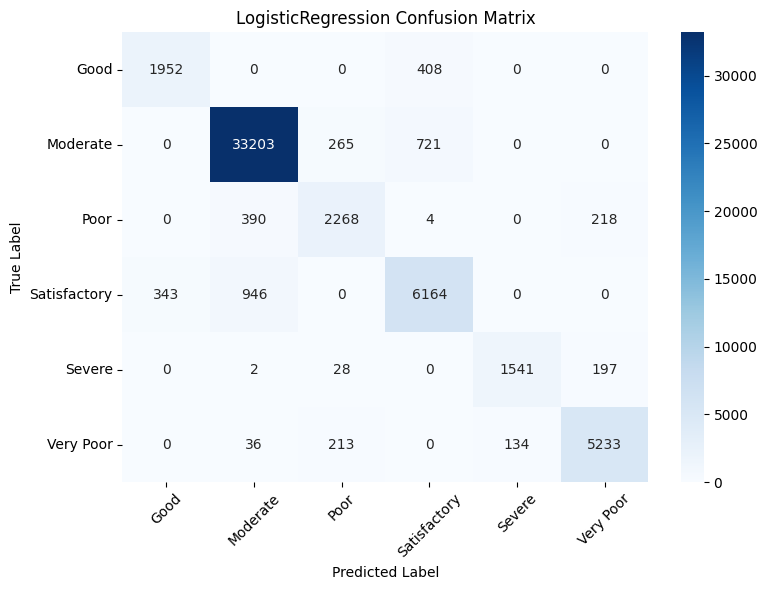


Evaluating Model: SVM

SVM Classification Report:
              precision    recall  f1-score   support

        Good     0.9062    0.8966    0.9014      2360
    Moderate     0.9922    0.9921    0.9921     34189
        Poor     0.9625    0.9549    0.9587      2880
Satisfactory     0.9392    0.9459    0.9426      7453
      Severe     0.9812    0.9734    0.9773      1768
   Very Poor     0.9835    0.9858    0.9846      5616

    accuracy                         0.9783     54266
   macro avg     0.9608    0.9581    0.9594     54266
weighted avg     0.9783    0.9783    0.9783     54266



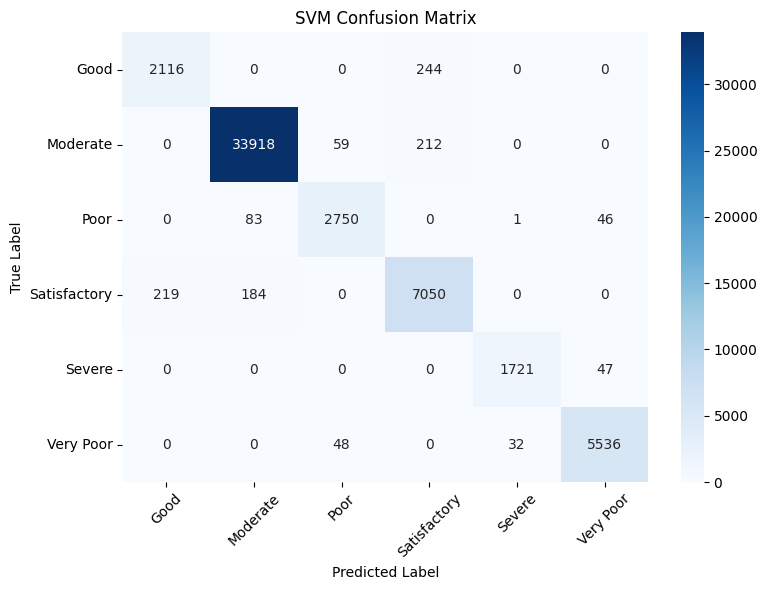


Evaluating Model: RandomForest

RandomForest Classification Report:
              precision    recall  f1-score   support

        Good     0.9497    0.9915    0.9701      2360
    Moderate     0.9999    0.9971    0.9985     34189
        Poor     0.9962    0.9986    0.9974      2880
Satisfactory     0.9886    0.9895    0.9891      7453
      Severe     1.0000    0.9989    0.9994      1768
   Very Poor     0.9998    0.9961    0.9979      5616

    accuracy                         0.9959     54266
   macro avg     0.9890    0.9953    0.9921     54266
weighted avg     0.9960    0.9959    0.9959     54266



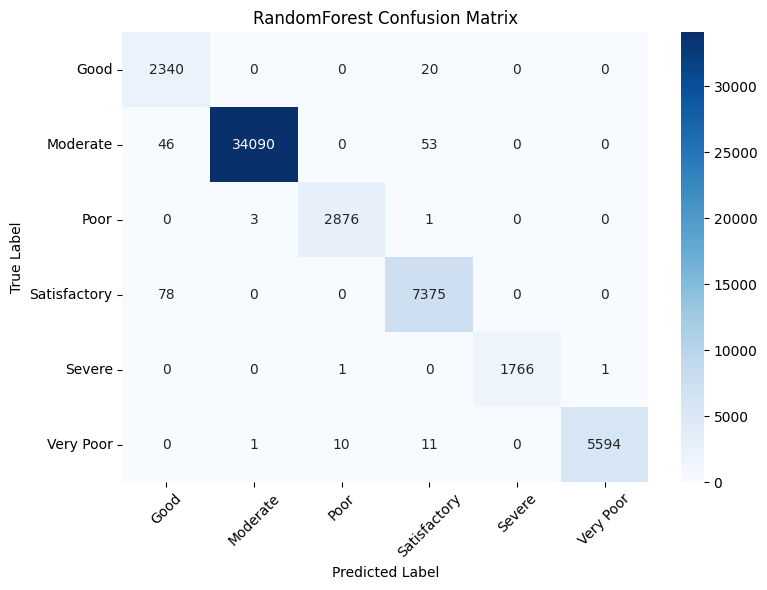


Evaluating Model: XGBoost

XGBoost Classification Report:
              precision    recall  f1-score   support

        Good     0.9987    0.9975    0.9981      2360
    Moderate     0.9985    0.9987    0.9986     34189
        Poor     0.9827    0.9882    0.9855      2880
Satisfactory     0.9968    0.9972    0.9970      7453
      Severe     0.9585    0.9666    0.9625      1768
   Very Poor     0.9878    0.9811    0.9845      5616

    accuracy                         0.9950     54266
   macro avg     0.9872    0.9882    0.9877     54266
weighted avg     0.9950    0.9950    0.9950     54266



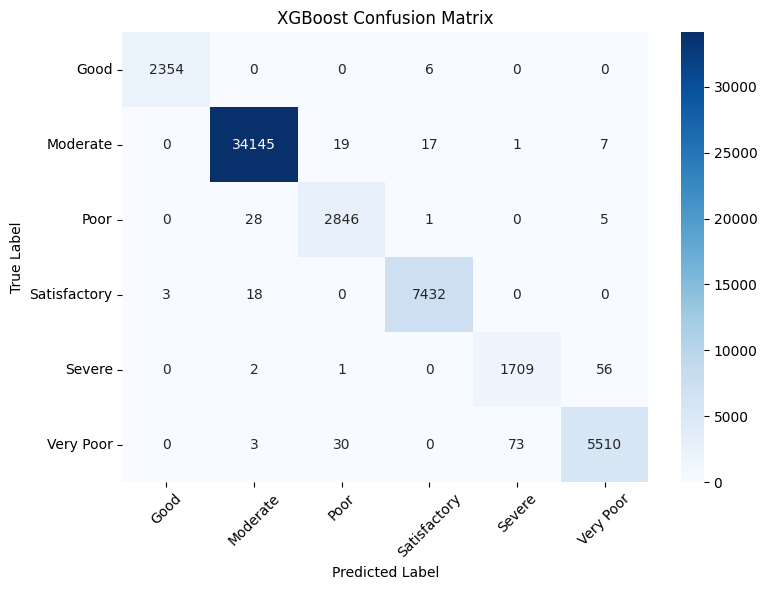


Evaluating Model: LightGBM
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.004288 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1530
[LightGBM] [Info] Number of data points in the train set: 217060, number of used features: 6
[LightGBM] [Info] Start training from score -3.135218
[LightGBM] [Info] Start training from score -0.462012
[LightGBM] [Info] Start training from score -2.936089
[LightGBM] [Info] Start training from score -1.985330
[LightGBM] [Info] Start training from score -3.423748
[LightGBM] [Info] Start training from score -2.268215

LightGBM Classification Report:
              precision    recall  f1-score   support

        Good     1.0000    0.9987    0.9994      2360
    Moderate     0.9987    0.9994    0.9990     34189
        Poor     0.9753    0.9715    0.9734      2880
Satisfactory     0.9989    0.9995    0.9992      7453
      Severe     0.9687    0.9802    0.9744      1768
 

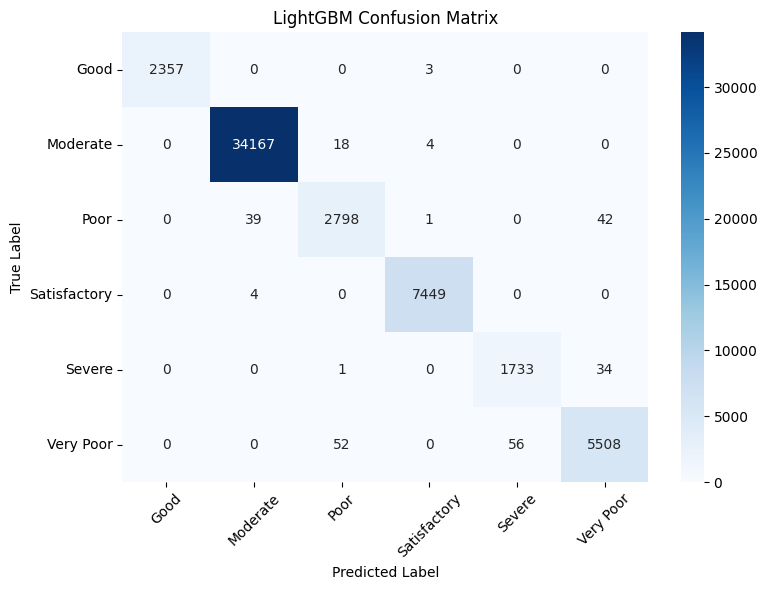


Evaluating Model: CatBoost

CatBoost Classification Report:
              precision    recall  f1-score   support

        Good     0.9987    1.0000    0.9994      2360
    Moderate     0.9993    0.9993    0.9993     34189
        Poor     0.9795    0.9934    0.9864      2880
Satisfactory     0.9985    0.9970    0.9978      7453
      Severe     0.9810    0.9921    0.9865      1768
   Very Poor     0.9953    0.9858    0.9905      5616

    accuracy                         0.9971     54266
   macro avg     0.9921    0.9946    0.9933     54266
weighted avg     0.9971    0.9971    0.9971     54266



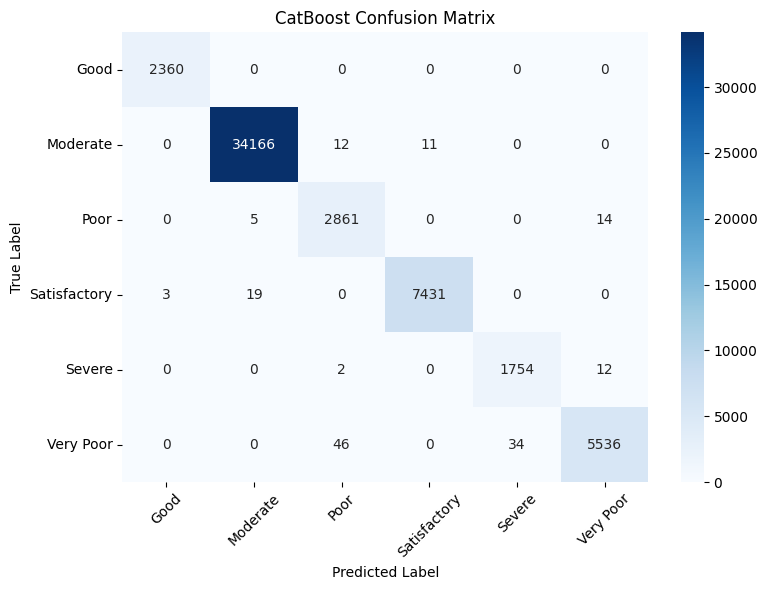


Evaluating Model: Bagging

Bagging Classification Report:
              precision    recall  f1-score   support

        Good     0.9948    0.9822    0.9885      2360
    Moderate     0.9979    0.9999    0.9989     34189
        Poor     0.9990    0.9979    0.9984      2880
Satisfactory     0.9945    0.9902    0.9923      7453
      Severe     1.0000    0.9994    0.9997      1768
   Very Poor     1.0000    0.9995    0.9997      5616

    accuracy                         0.9976     54266
   macro avg     0.9977    0.9949    0.9963     54266
weighted avg     0.9976    0.9976    0.9976     54266



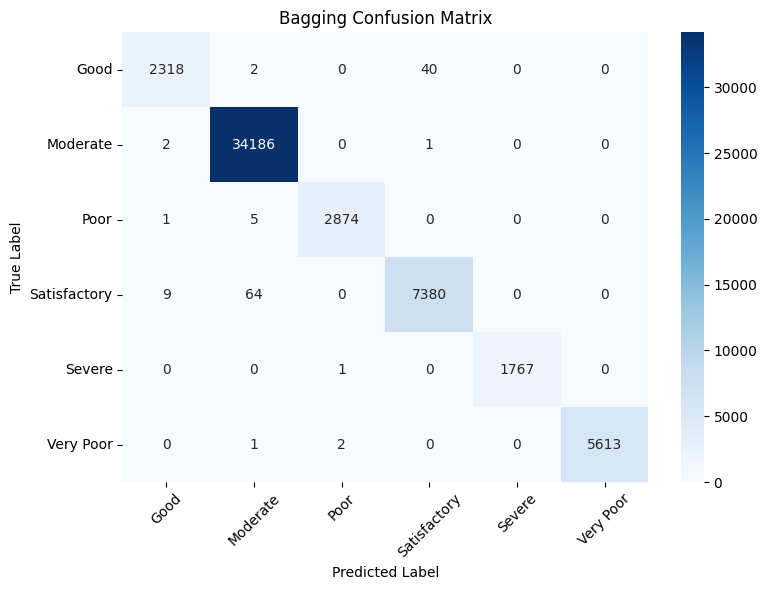


Evaluating Model: AdaBoost

AdaBoost Classification Report:
              precision    recall  f1-score   support

        Good     0.0000    0.0000    0.0000      2360
    Moderate     0.8445    0.9854    0.9095     34189
        Poor     0.4261    0.9354    0.5855      2880
Satisfactory     0.3554    0.2014    0.2571      7453
      Severe     1.0000    0.8445    0.9157      1768
   Very Poor     0.9262    0.3846    0.5435      5616

    accuracy                         0.7655     54266
   macro avg     0.5920    0.5586    0.5352     54266
weighted avg     0.7319    0.7655    0.7255     54266



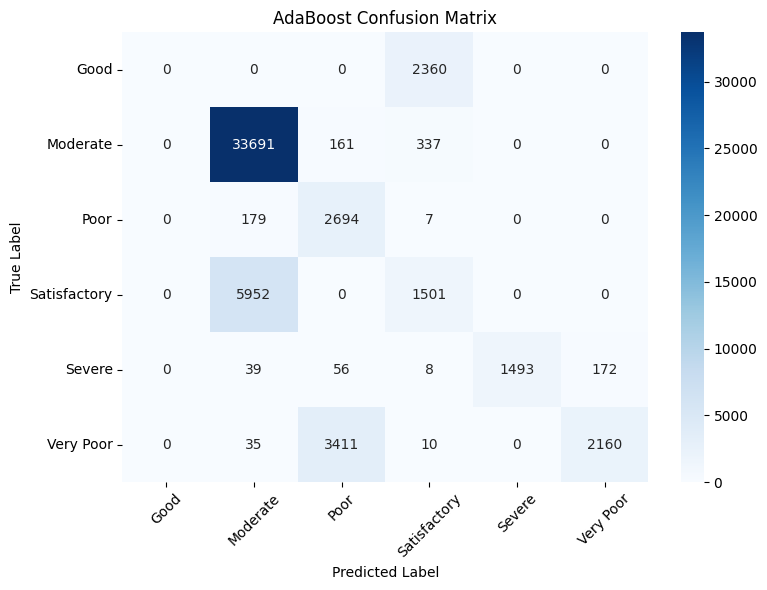


=== Overall Model Performance Comparison ===
             Model  Train Accuracy  Test Accuracy  Train Macro F1  Macro Precision  Macro Recall  Macro F1  Macro AP  Weighted F1  Balanced Accuracy  Training Time (s)  Inference Time (s)
           Bagging          0.9999         0.9976          0.9999           0.9977        0.9949    0.9963    0.9992       0.9976             0.9949             5.9314              0.0848
          CatBoost          0.9993         0.9971          0.9984           0.9921        0.9946    0.9933    0.9998       0.9971             0.9946            42.1112              0.1040
      RandomForest          0.9958         0.9959          0.9925           0.9890        0.9953    0.9921    0.9987       0.9959             0.9953            30.4297              0.2396
          LightGBM          1.0000         0.9953          0.9999           0.9880        0.9883    0.9882    0.9994       0.9953             0.9883             2.8999              0.3607
           XGB

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    average_precision_score
)
from sklearn.preprocessing import label_binarize

# ============================================================
# STEP 1: Evaluate Models
# ============================================================

results = []
class_results = []

class_names = [str(c) for c in label_enc.classes_]
class_labels = np.arange(len(class_names))

# Convert true test labels to one-vs-rest format for AP
y_test_bin = label_binarize(
    y_test,
    classes=class_labels
)

for name, model in models.items():

    print(f"\n{'='*60}")
    print(f"Evaluating Model: {name}")
    print(f"{'='*60}")

    # --------------------------------------------------------
    # Train Model
    # --------------------------------------------------------

    start_train = time.perf_counter()

    model.fit(X_train, y_train)

    train_time = time.perf_counter() - start_train

    # --------------------------------------------------------
    # Predictions
    # --------------------------------------------------------

    y_train_pred = model.predict(X_train)

    start_test = time.perf_counter()
    y_pred = model.predict(X_test)
    inference_time = time.perf_counter() - start_test

    # --------------------------------------------------------
    # Get class scores for Average Precision
    # --------------------------------------------------------

    macro_ap = np.nan

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)

    elif hasattr(model, "decision_function"):
        y_score = model.decision_function(X_test)

    else:
        y_score = None
        print(
            f"Macro AP not calculated for {name}: "
            "the model has no predict_proba or decision_function method."
        )

    if y_score is not None:
        model_classes = getattr(model, "classes_", class_labels)

        # Align score columns with class_labels
        if np.ndim(y_score) == 2:
            aligned_scores = np.zeros(
                (len(y_test), len(class_labels)),
                dtype=float
            )

            for score_col, class_id in enumerate(model_classes):
                class_index = int(class_id)

                if 0 <= class_index < len(class_labels):
                    aligned_scores[:, class_index] = y_score[:, score_col]

            y_score = aligned_scores

            # Macro AP for multiclass scores
            if y_test_bin.shape[1] == len(class_labels):
                macro_ap = average_precision_score(
                    y_test_bin,
                    y_score,
                    average="macro"
                )

            # Binary label_binarize produces one column
            elif len(class_labels) == 2 and y_test_bin.shape[1] == 1:
                macro_ap = average_precision_score(
                    y_test_bin[:, 0],
                    y_score[:, 1]
                )

    # --------------------------------------------------------
    # Evaluation Metrics
    # --------------------------------------------------------

    train_acc = accuracy_score(y_train, y_train_pred)

    train_macro_f1 = f1_score(
        y_train,
        y_train_pred,
        average="macro",
        zero_division=0
    )

    acc = accuracy_score(y_test, y_pred)

    macro_precision = precision_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    macro_recall = recall_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_test,
        y_pred
    )

    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------

    results.append({
        "Model": name,
        "Train Accuracy": train_acc,
        "Test Accuracy": acc,
        "Train Macro F1": train_macro_f1,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1": macro_f1,
        "Macro AP": macro_ap,
        "Weighted F1": weighted_f1,
        "Balanced Accuracy": balanced_acc,
        "Training Time (s)": train_time,
        "Inference Time (s)": inference_time
    })

    # --------------------------------------------------------
    # Classification Report
    # --------------------------------------------------------

    print(f"\n{name} Classification Report:")

    print(
        classification_report(
            y_test,
            y_pred,
            labels=class_labels,
            target_names=class_names,
            digits=4,
            zero_division=0
        )
    )

    # Store per-class metrics
    report = classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    for cls in class_names:
        class_results.append({
            "Model": name,
            "Class": cls,
            "Precision": report[cls]["precision"],
            "Recall": report[cls]["recall"],
            "F1 Score": report[cls]["f1-score"],
            "Support": report[cls]["support"]
        })

    # --------------------------------------------------------
    # Confusion Matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(f"{name} Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


# ============================================================
# STEP 2: Overall Model Comparison
# ============================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("\n=== Overall Model Performance Comparison ===")
print(results_df.round(4).to_string(index=False))


# ============================================================
# STEP 3: Per-Class Performance Comparison
# ============================================================

class_results_df = pd.DataFrame(class_results)

print("\n=== Per-Class Performance ===")
print(class_results_df.round(4).to_string(index=False))

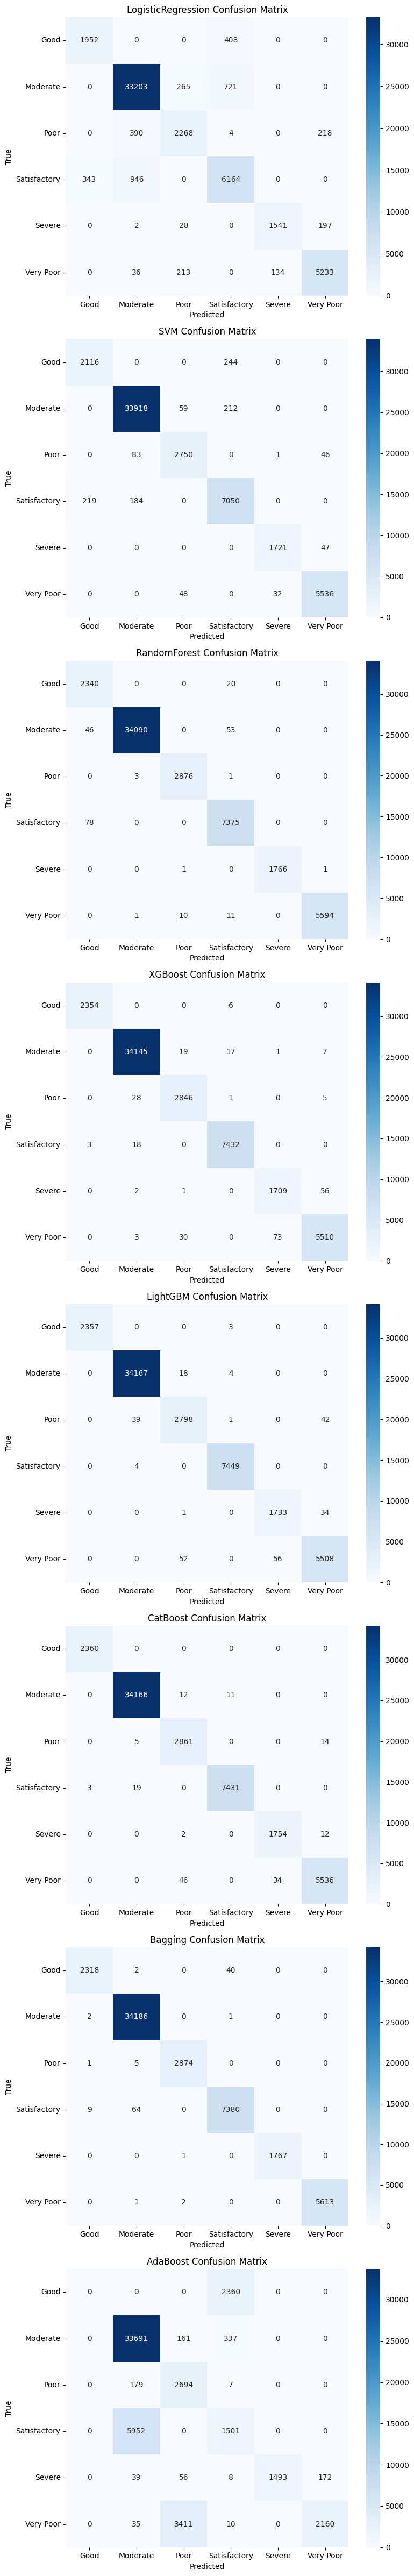

In [ ]:
num_models = len(models)
num_cols = 1  # One plot per row

plt.figure(figsize=(8, 6 * num_models))

for i, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    ax = plt.subplot(num_models, num_cols, i + 1)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_enc.classes_, yticklabels=label_enc.classes_, ax=ax)
    ax.set_title(f'{name} Confusion Matrix')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.tight_layout()
plt.show()

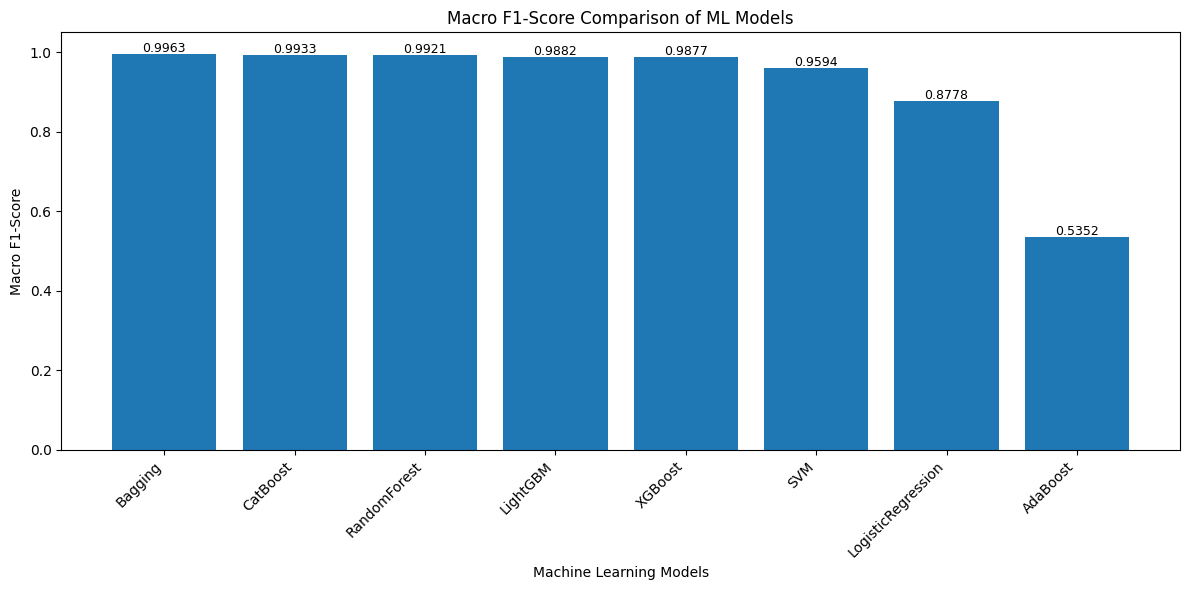


=== RESULTS SAVED SUCCESSFULLY ===
Directory: /content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New
Saved: /content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New/All_Models_Overall_Performance.csv
Saved: /content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New/All_Models_Classwise_Performance.csv
Saved: /content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New/All_Models_Macro_F1_Comparison.png

=== OVERALL PERFORMANCE RESULTS ===
             Model  Train Accuracy  Test Accuracy  Train Macro F1  Macro Precision  Macro Recall  Macro F1  Macro AP  Weighted F1  Balanced Accuracy  Training Time (s)  Inference Time (s)
           Bagging        0.999949       0.997641        0.999909         0.997697      0.994856  0.996269  0.999222     0.997636           0.994856           5.931424            0.084801
          CatBoost        0.999281       0.997088        0.998409         0.992053      0.994602  0.

In [ ]:
# ============================================================
# SAVE PERFORMANCE RESULTS TO GOOGLE DRIVE DATASET FOLDER
# =============================================================

from google.colab import drive
from pathlib import Path
import matplotlib.pyplot as plt

# Dataset directory
SAVE_DIR = Path(
    "/content/drive/MyDrive/My work/"
    "Air Quality Project/Paper 1(External Data)/New/"
)

SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 1. SAVE OVERALL PERFORMANCE RESULTS
# ============================================================

results_df.to_csv(
    SAVE_DIR / "All_Models_Overall_Performance.csv",
    index=False
)

# ============================================================
# 2. SAVE CLASS-WISE PERFORMANCE RESULTS
# ============================================================

class_results_df.to_csv(
    SAVE_DIR / "All_Models_Classwise_Performance.csv",
    index=False
)

# ============================================================
# 3. SAVE MACRO F1 COMPARISON FIGURE
# ============================================================

plot_df = results_df.sort_values(
    "Macro F1",
    ascending=False
)

plt.figure(figsize=(12, 6))

bars = plt.bar(
    plot_df["Model"],
    plot_df["Macro F1"]
)

plt.xlabel("Machine Learning Models")
plt.ylabel("Macro F1-Score")
plt.title("Macro F1-Score Comparison of ML Models")

plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")

for bar, value in zip(bars, plot_df["Macro F1"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.005,
        f"{value:.4f}",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    SAVE_DIR / "All_Models_Macro_F1_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 4. CONFIRM SAVED FILES
# ============================================================

print("\n=== RESULTS SAVED SUCCESSFULLY ===")
print("Directory:", SAVE_DIR)

for filename in [
    "All_Models_Overall_Performance.csv",
    "All_Models_Classwise_Performance.csv",
    "All_Models_Macro_F1_Comparison.png"
]:
    print("Saved:", SAVE_DIR / filename)

print("\n=== OVERALL PERFORMANCE RESULTS ===")
print(results_df.round(6).to_string(index=False))

print("\n=== CLASS-WISE PERFORMANCE RESULTS ===")
print(class_results_df.round(6).to_string(index=False))

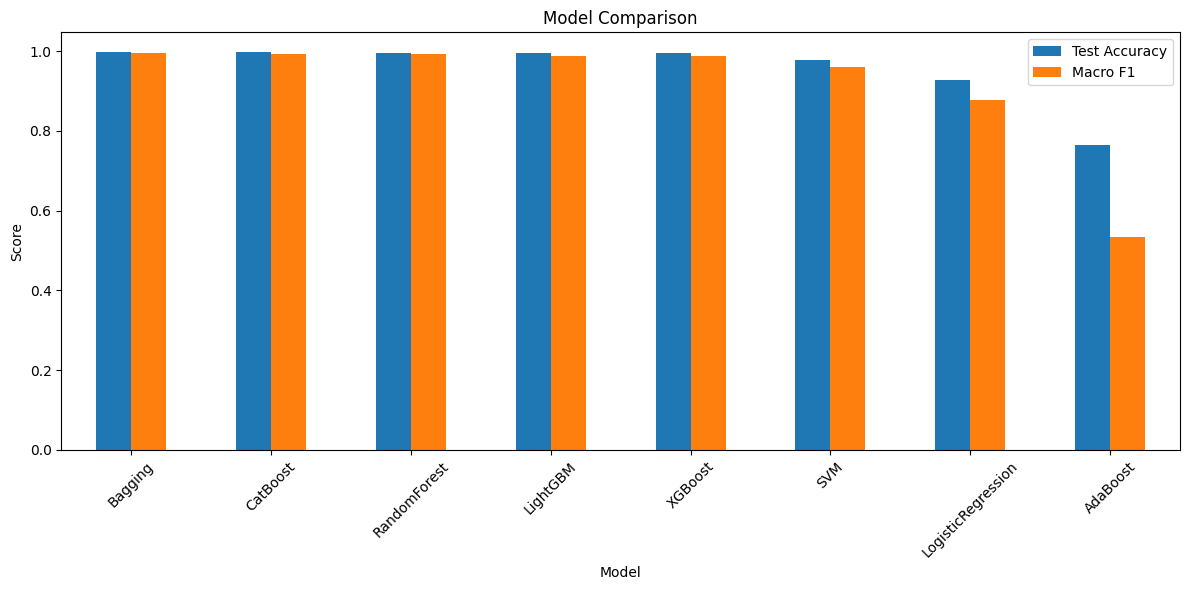

In [ ]:
# Summary plot
summary_df = pd.DataFrame(results)
summary_df = summary_df.sort_values(by='Test Accuracy', ascending=False)
summary_df.plot(x='Model', y=['Test Accuracy', 'Macro F1'], kind='bar', figsize=(12,6))
plt.title('Model Comparison')
plt.ylabel('Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Save results
summary_df.to_csv('classification_model_comparison.csv', index=False)

# Task
Apply t-SNE to the predictions of each model and visualize the results.

In [ ]:
model_predictions = {}
for name, model in models.items():
    try:
        # Try to get probabilities
        y_pred_proba = model.predict_proba(X_test)
        model_predictions[name] = y_pred_proba
        print(f"Obtained probabilities for {name}")
    except AttributeError:
        try:
            # If no probabilities, try to get decision function
            y_pred_decision = model.decision_function(X_test)
            model_predictions[name] = y_pred_decision
            print(f"Obtained decision function for {name}")
        except AttributeError:
            # If neither is available, skip the model for t-SNE
            print(f"Skipping {name} as it does not have predict_proba or decision_function")


Obtained probabilities for LogisticRegression
Obtained probabilities for SVM
Obtained probabilities for RandomForest
Obtained probabilities for XGBoost
Obtained probabilities for LightGBM
Obtained probabilities for CatBoost
Obtained probabilities for Bagging
Obtained probabilities for AdaBoost


In [ ]:
from sklearn.manifold import TSNE

tsne_results = {}
for name, predictions in model_predictions.items():
    print(f"Applying t-SNE to {name} predictions...")
    try:
        # Adjust perplexity based on the number of samples if necessary
        perplexity_val = min(30, predictions.shape[0] - 1)
        tsne = TSNE(n_components=2, random_state=42, perplexity=perplexity_val, n_iter=300)
        tsne_transformed = tsne.fit_transform(predictions)
        tsne_results[name] = tsne_transformed
        print(f"t-SNE transformation complete for {name}.")
    except Exception as e:
        print(f"Could not apply t-SNE to {name}: {e}")


Applying t-SNE to LogisticRegression predictions...
t-SNE transformation complete for LogisticRegression.
Applying t-SNE to SVM predictions...
t-SNE transformation complete for SVM.
Applying t-SNE to RandomForest predictions...
t-SNE transformation complete for RandomForest.
Applying t-SNE to XGBoost predictions...
t-SNE transformation complete for XGBoost.
Applying t-SNE to LightGBM predictions...
t-SNE transformation complete for LightGBM.
Applying t-SNE to CatBoost predictions...
t-SNE transformation complete for CatBoost.
Applying t-SNE to Bagging predictions...
t-SNE transformation complete for Bagging.
Applying t-SNE to AdaBoost predictions...
t-SNE transformation complete for AdaBoost.


## Visualize t-sne results




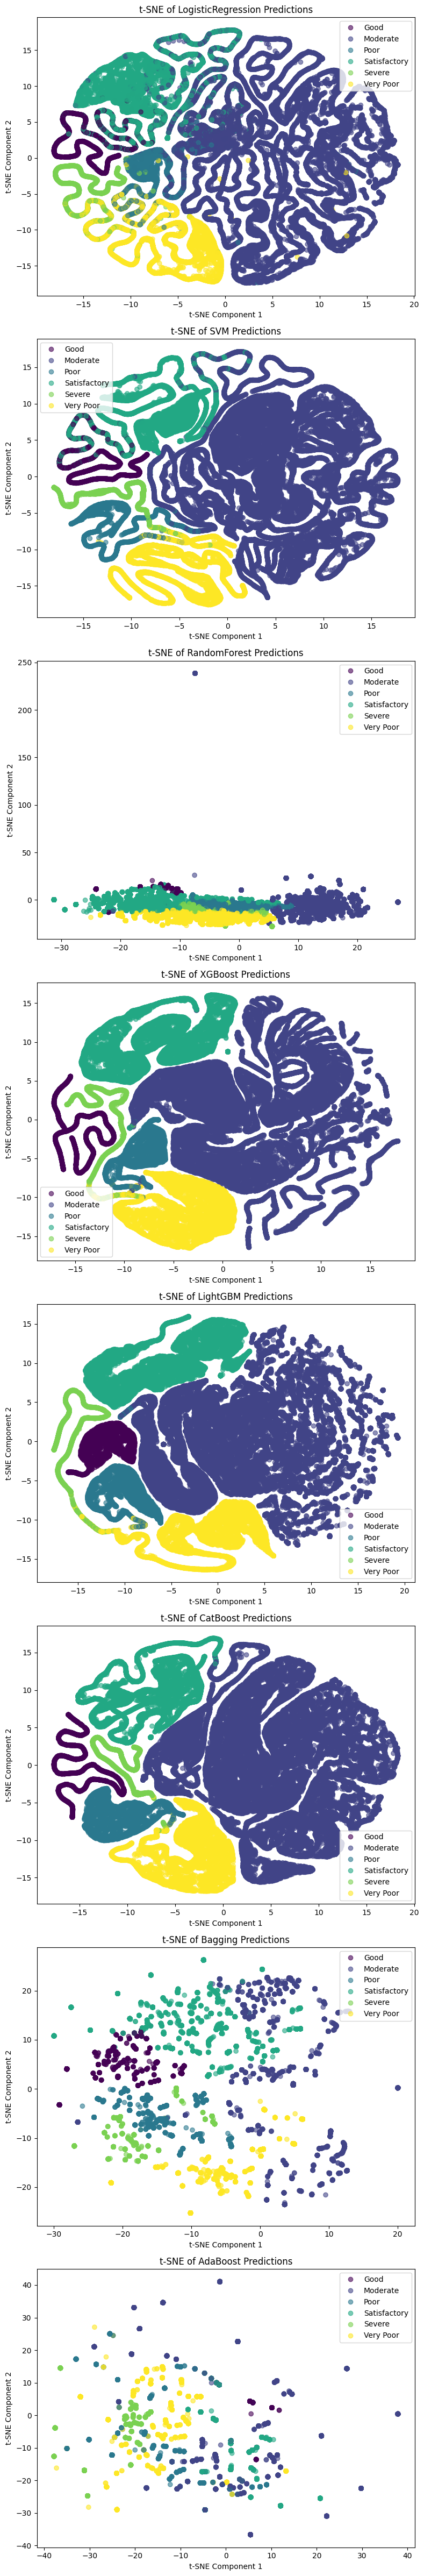

In [ ]:
plt.figure(figsize=(8, 6 * len(tsne_results)))
num_cols = 1

for i, (name, tsne_data) in enumerate(tsne_results.items()):
    ax = plt.subplot(len(tsne_results), num_cols, i + 1)
    scatter = ax.scatter(tsne_data[:, 0], tsne_data[:, 1], c=y_test, cmap='viridis', alpha=0.6)
    ax.set_title(f't-SNE of {name} Predictions')
    ax.set_xlabel('t-SNE Component 1')
    ax.set_ylabel('t-SNE Component 2')
    # Correctly get legend handles and labels from the scatter plot
    handles, _ = scatter.legend_elements()
    ax.legend(handles=handles, labels=list(label_enc.classes_)) # Convert labels to a list
plt.tight_layout()
plt.show()

## Calculate roc curve and auc for each model




In [ ]:
from sklearn.metrics import roc_curve, auc
import pandas as pd

roc_data = {}
for name, model in models.items():
    try:
        # Get predicted probabilities
        y_pred_proba = model.predict_proba(X_test)

        # Calculate ROC and AUC for each class
        roc_data[name] = {}
        for i in range(len(label_enc.classes_)):
            fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba[:, i], pos_label=i)
            roc_auc = auc(fpr, tpr)
            roc_data[name][label_enc.classes_[i]] = {'fpr': fpr, 'tpr': tpr, 'auc': roc_auc}
        print(f"Calculated ROC and AUC for {name}")

    except AttributeError:
        print(f"Skipping {name} as it does not have predict_proba")


Calculated ROC and AUC for LogisticRegression
Calculated ROC and AUC for SVM
Calculated ROC and AUC for RandomForest
Calculated ROC and AUC for XGBoost
Calculated ROC and AUC for LightGBM
Calculated ROC and AUC for CatBoost
Calculated ROC and AUC for Bagging
Calculated ROC and AUC for AdaBoost


## Plot roc curves




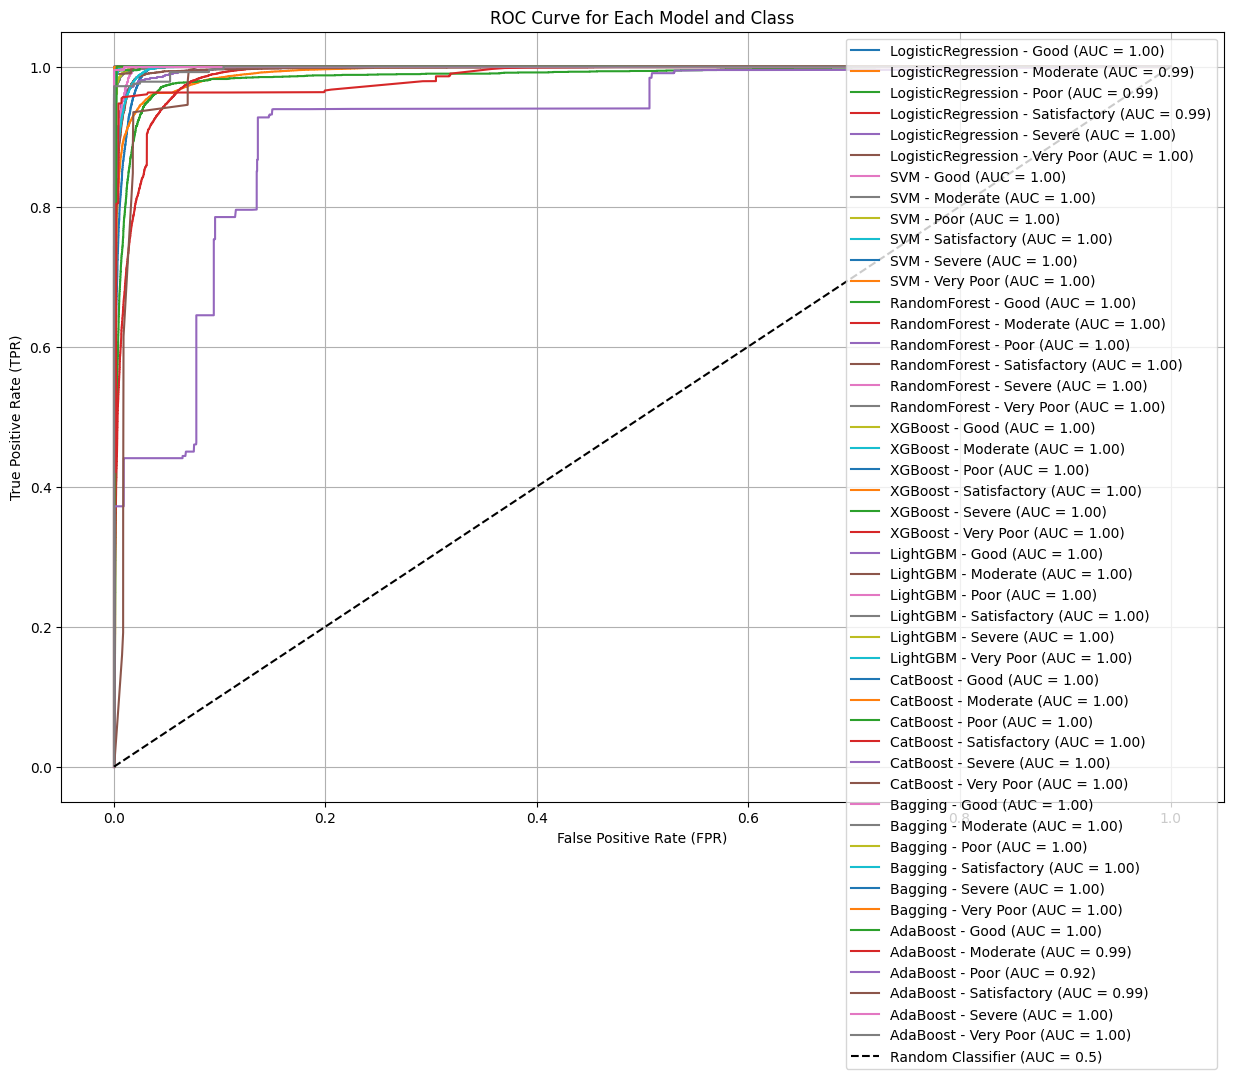

In [ ]:
plt.figure(figsize=(15, 10))
for name, class_roc_data in roc_data.items():
    for class_name, data in class_roc_data.items():
        plt.plot(data['fpr'], data['tpr'], label=f'{name} - {class_name} (AUC = {data["auc"]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5)')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve for Each Model and Class')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
auc_results = []
for name, class_roc_data in roc_data.items():
    average_auc = np.mean([data['auc'] for data in class_roc_data.values()])
    auc_results.append({'Model': name, 'Average AUC': average_auc})

auc_summary_df = pd.DataFrame(auc_results)
auc_summary_df = auc_summary_df.sort_values(by='Average AUC', ascending=False)
display(auc_summary_df)

,Model,Average AUC
5,CatBoost,0.999988
4,LightGBM,0.999963
3,XGBoost,0.999957
6,Bagging,0.999949
2,RandomForest,0.999901
1,SVM,0.999328
0,LogisticRegression,0.993128
7,AdaBoost,0.981410


In [ ]:
from sklearn.metrics import roc_curve, auc
import pandas as pd

class_roc_data = {}
for name, model in models.items():
    try:
        # Get predicted probabilities
        y_pred_proba = model.predict_proba(X_test)

        # Calculate ROC and AUC for each class
        class_roc_data[name] = {}
        for i in range(len(label_enc.classes_)):
            fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba[:, i], pos_label=i)
            roc_auc = auc(fpr, tpr)
            class_roc_data[name][label_enc.classes_[i]] = {'fpr': fpr, 'tpr': tpr, 'auc': roc_auc}
        print(f"Calculated class-wise ROC and AUC for {name}")

    except AttributeError:
        print(f"Skipping {name} as it does not have predict_proba")

Calculated class-wise ROC and AUC for LogisticRegression
Calculated class-wise ROC and AUC for SVM
Calculated class-wise ROC and AUC for RandomForest
Calculated class-wise ROC and AUC for XGBoost
Calculated class-wise ROC and AUC for LightGBM
Calculated class-wise ROC and AUC for CatBoost
Calculated class-wise ROC and AUC for Bagging
Calculated class-wise ROC and AUC for AdaBoost


## Plot class-wise roc curves


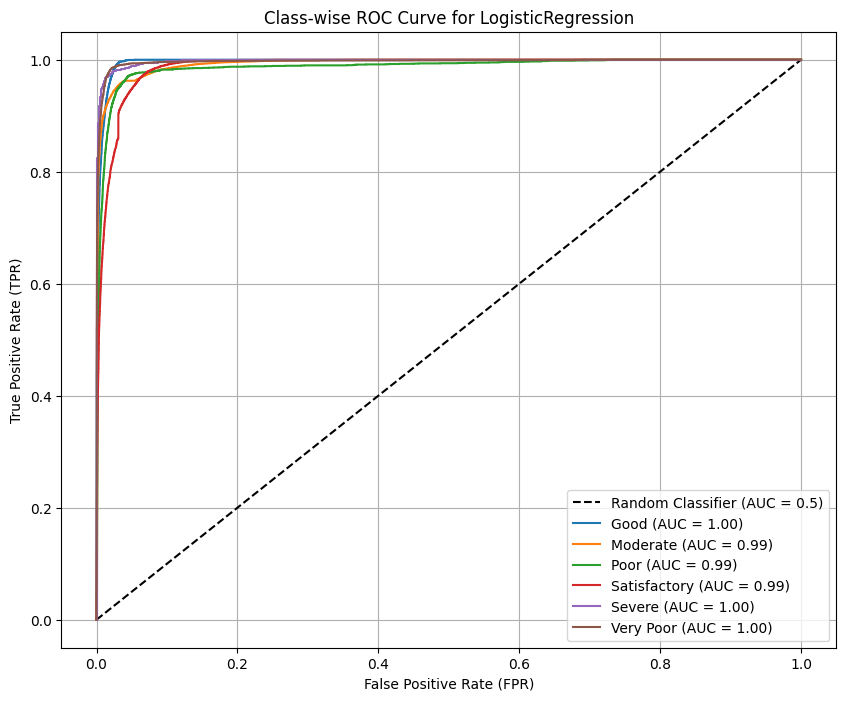

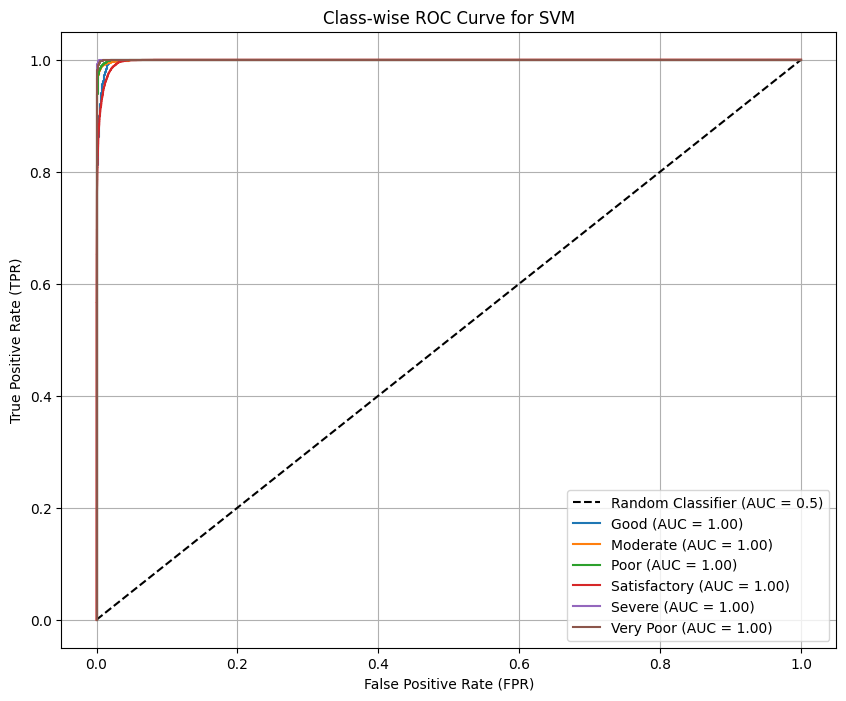

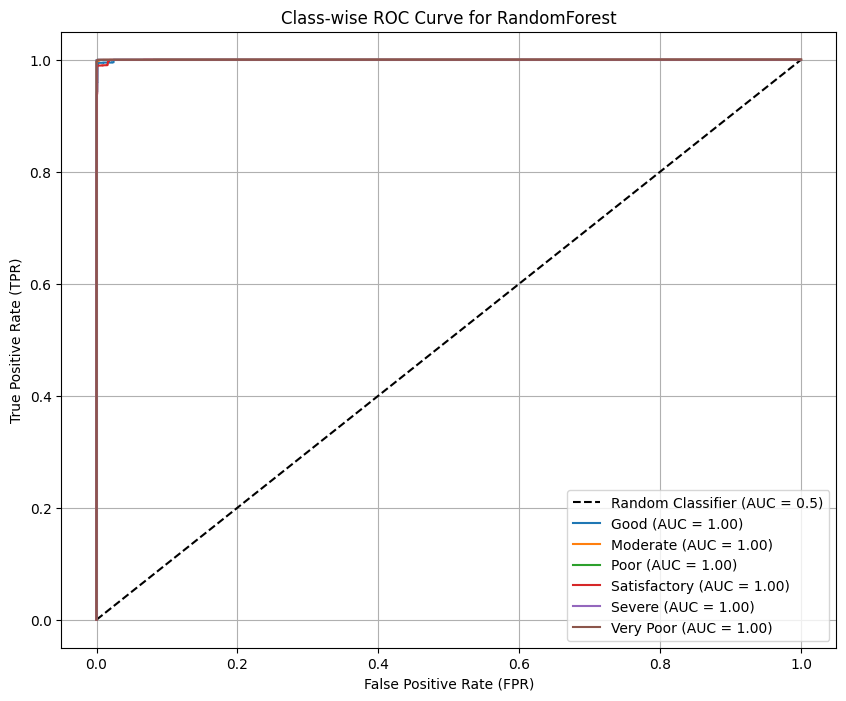

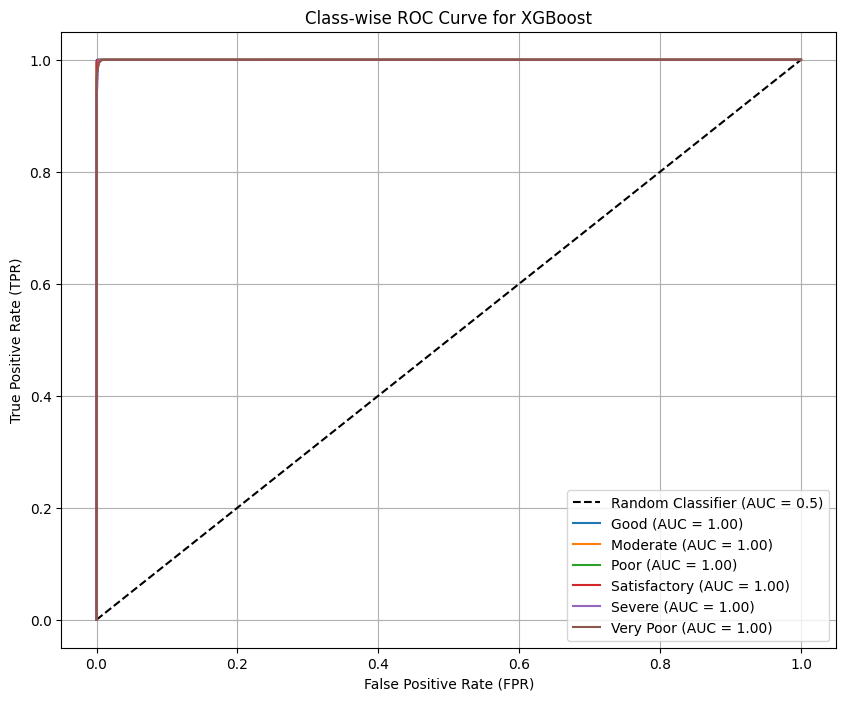

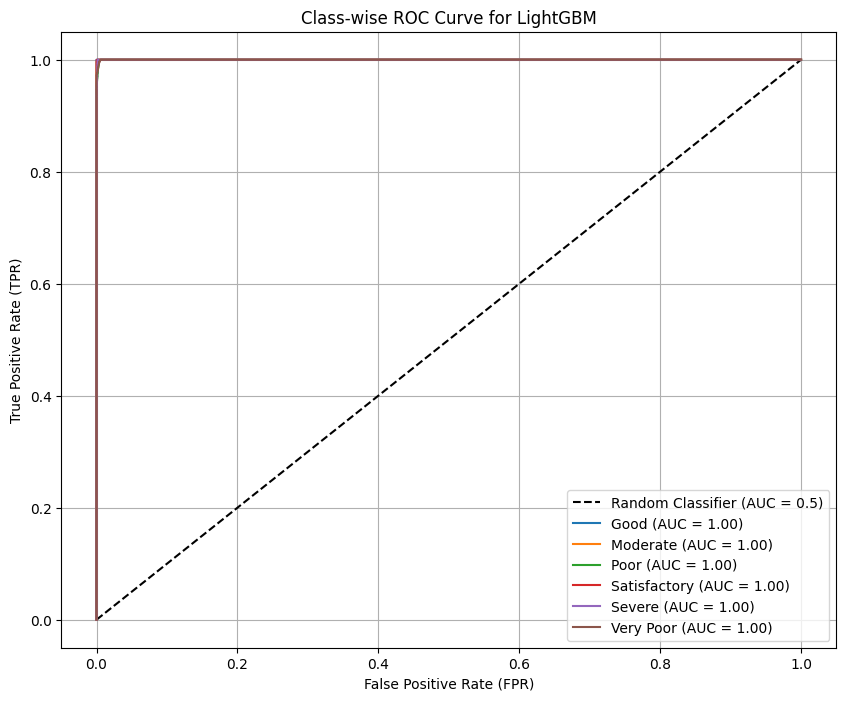

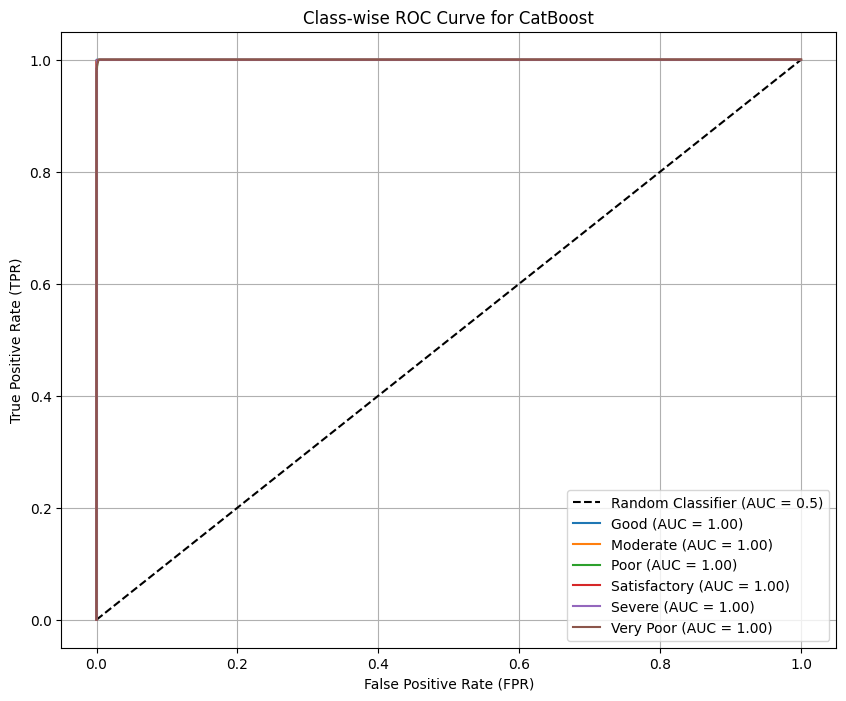

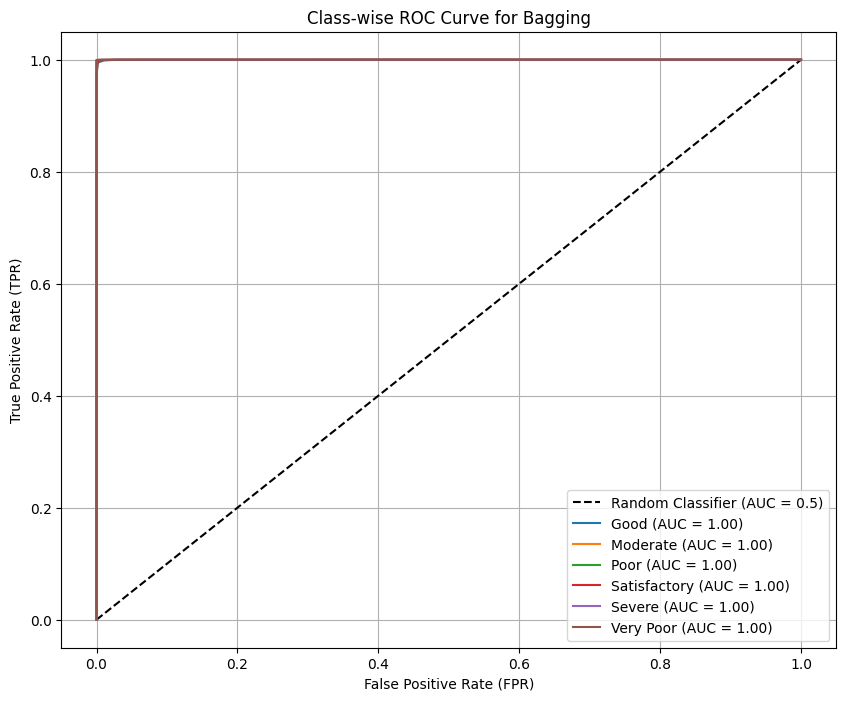

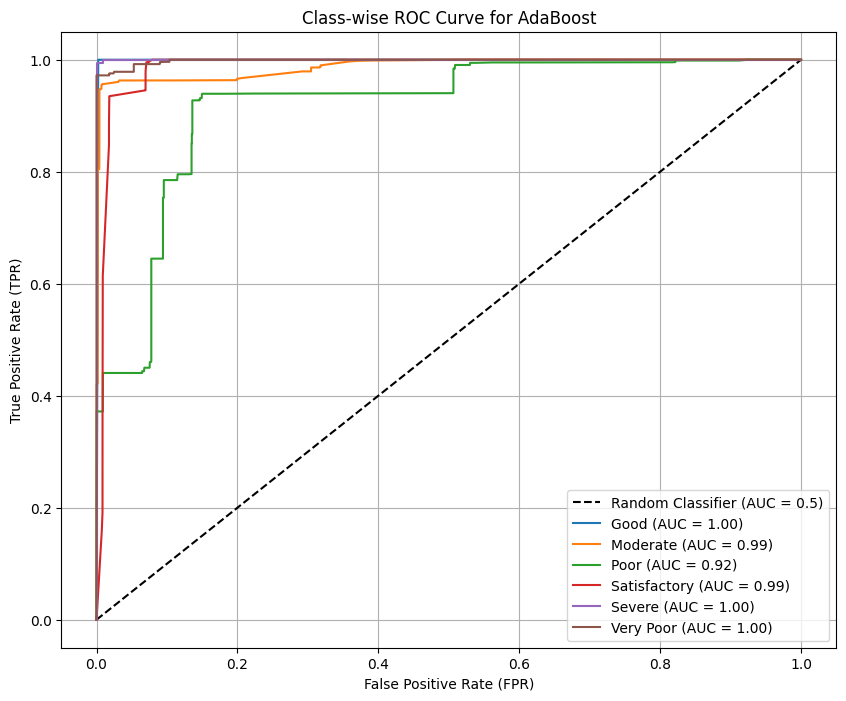

In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np

n_classes = len(label_enc.classes_)

for name, model in models.items():
    try:
        # Get predicted probabilities
        y_pred_proba = model.predict_proba(X_test)

        plt.figure(figsize=(10, 8))
        ax = plt.gca() # Get current axes

        ax.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5)')
        for i in range(n_classes):
            fpr, tpr, _ = roc_curve(y_test, y_pred_proba[:, i], pos_label=i)
            roc_auc = auc(fpr, tpr)
            ax.plot(fpr, tpr, label=f'{label_enc.classes_[i]} (AUC = {roc_auc:.2f})')

        ax.set_title(f'Class-wise ROC Curve for {name}')
        ax.set_xlabel('False Positive Rate (FPR)')
        ax.set_ylabel('True Positive Rate (TPR)')
        ax.legend(loc='lower right')
        ax.grid(True)
        plt.show()

    except AttributeError:
        print(f"Skipping {name} as it does not have predict_proba")
        continue

## Calculate precision-recall curves




In [ ]:
from sklearn.metrics import precision_recall_curve

pr_data = {}
for name, model in models.items():
    try:
        # Get predicted probabilities
        y_pred_proba = model.predict_proba(X_test)

        # Calculate Precision-Recall for each class
        pr_data[name] = {}
        for i in range(len(label_enc.classes_)):
            precision, recall, thresholds = precision_recall_curve(y_test == i, y_pred_proba[:, i])
            pr_data[name][label_enc.classes_[i]] = {'precision': precision, 'recall': recall, 'thresholds': thresholds}
        print(f"Calculated Precision and Recall for {name}")

    except AttributeError:
        print(f"Skipping {name} as it does not have predict_proba")

Calculated Precision and Recall for LogisticRegression
Calculated Precision and Recall for SVM
Calculated Precision and Recall for RandomForest
Calculated Precision and Recall for XGBoost
Calculated Precision and Recall for LightGBM
Calculated Precision and Recall for CatBoost
Calculated Precision and Recall for Bagging
Calculated Precision and Recall for AdaBoost


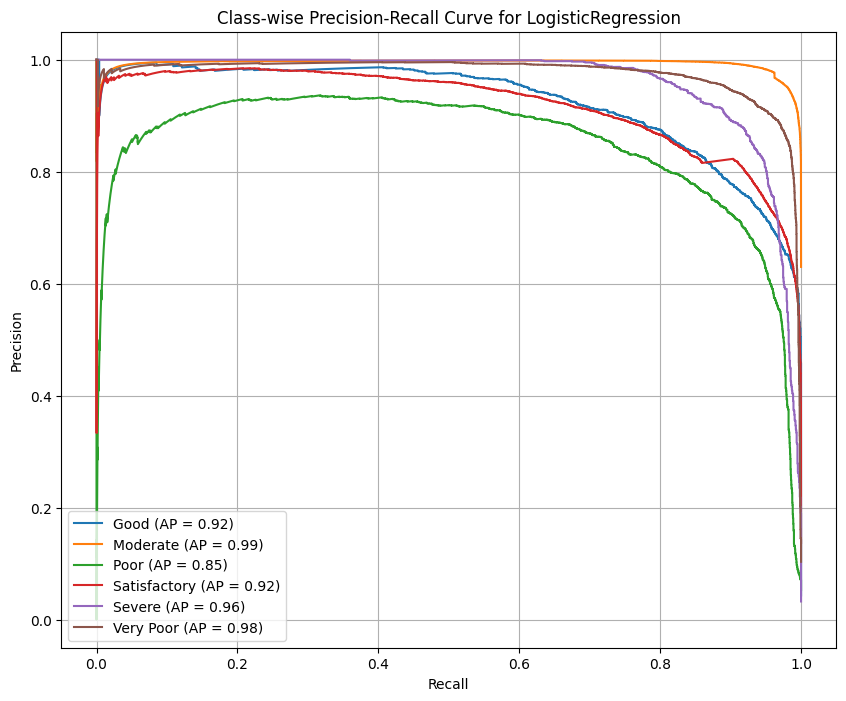

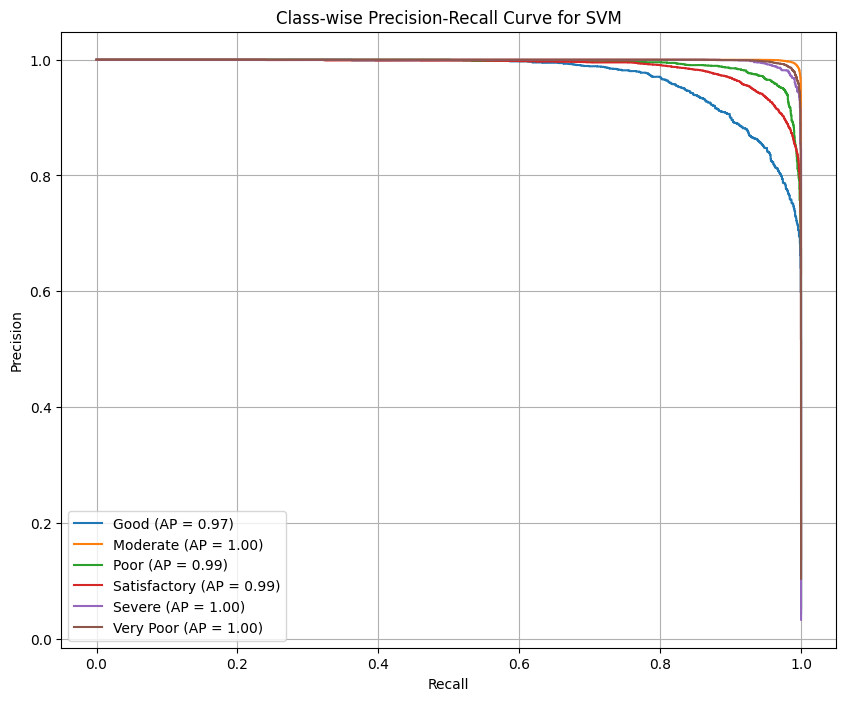

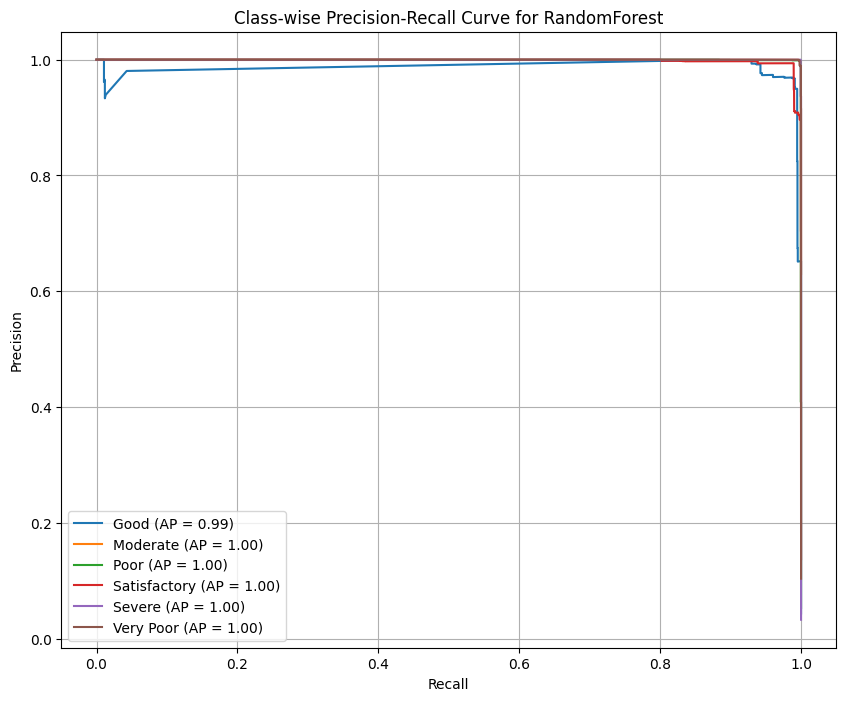

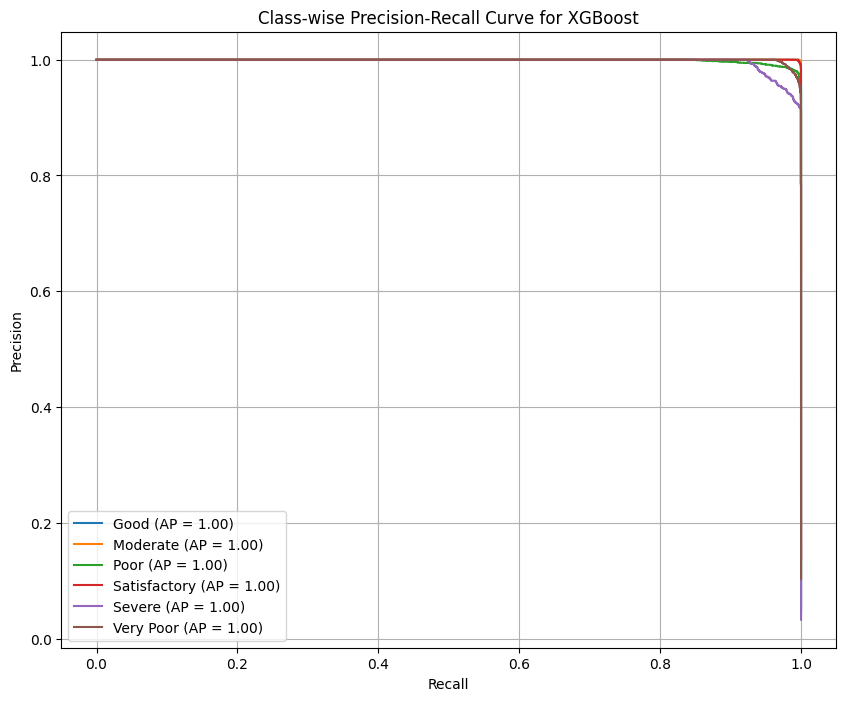

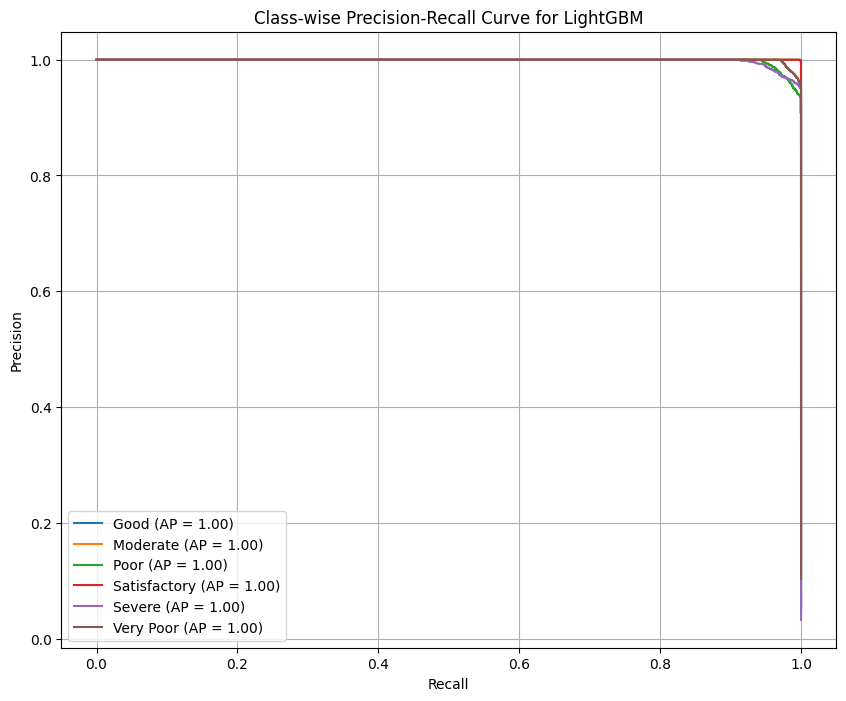

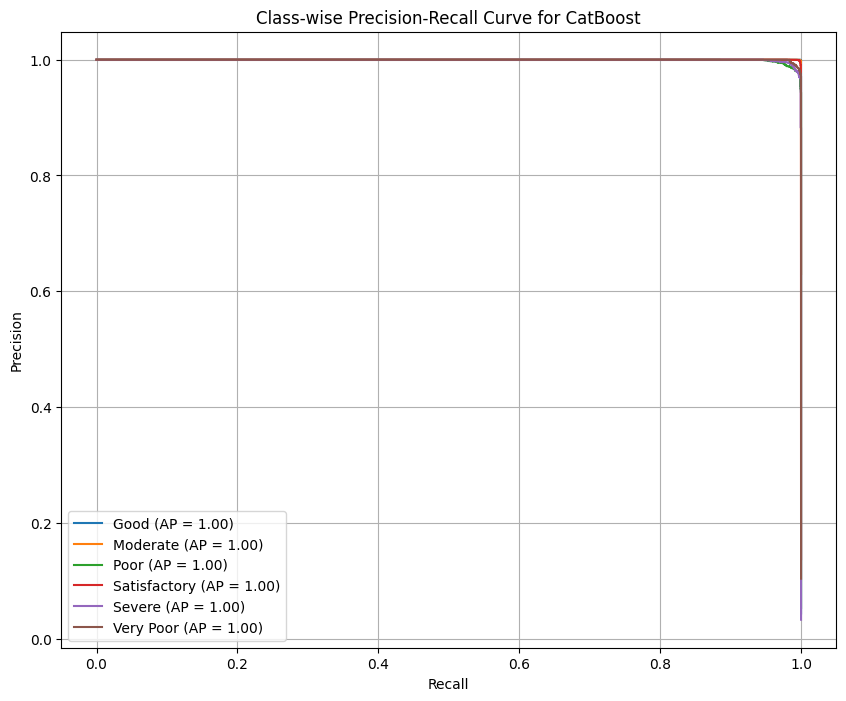

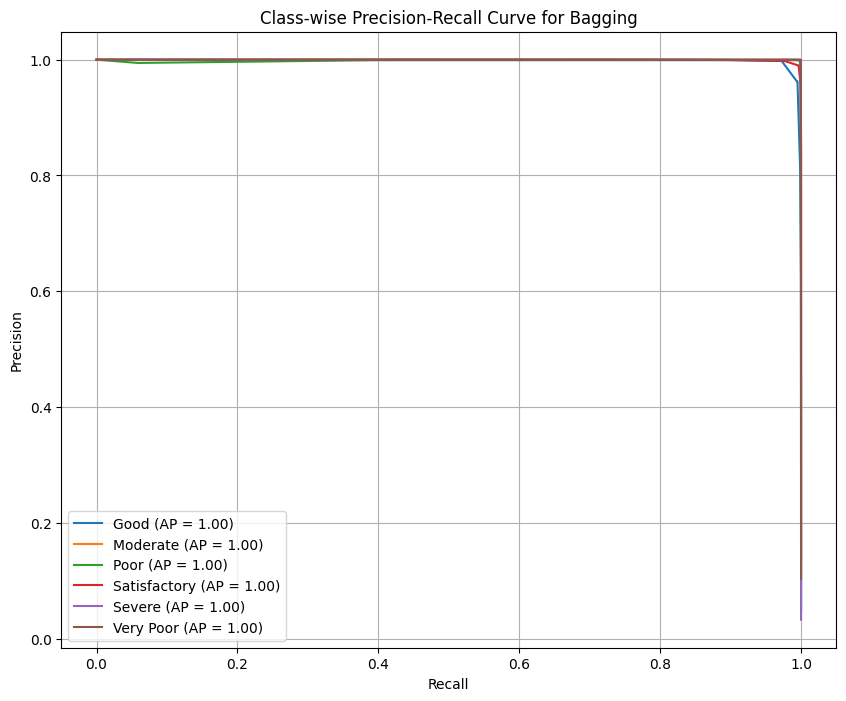

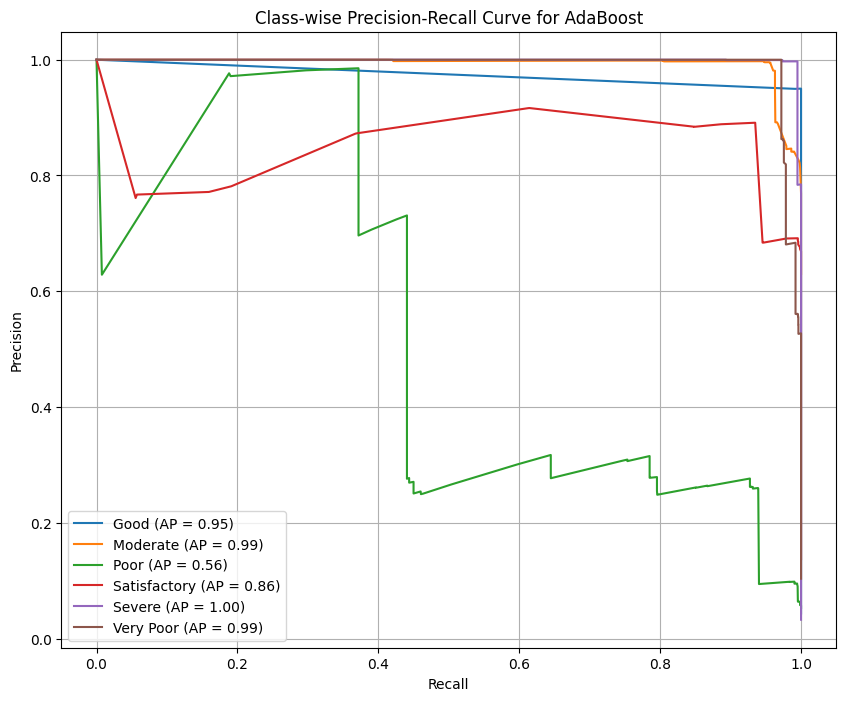

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt
import numpy as np

for name, model in models.items():
    try:
        # Get predicted probabilities
        y_pred_proba = model.predict_proba(X_test)

        plt.figure(figsize=(10, 8))
        ax = plt.gca() # Get current axes

        for i in range(len(label_enc.classes_)):
            precision, recall, _ = precision_recall_curve(y_test == i, y_pred_proba[:, i])
            average_precision = average_precision_score(y_test == i, y_pred_proba[:, i])
            ax.plot(recall, precision, label=f'{label_enc.classes_[i]} (AP = {average_precision:.2f})')

        ax.set_title(f'Class-wise Precision-Recall Curve for {name}')
        ax.set_xlabel('Recall')
        ax.set_ylabel('Precision')
        ax.legend(loc='lower left')
        ax.grid(True)
        plt.show()

    except AttributeError:
        print(f"Skipping {name} as it does not have predict_proba")
        continue

## Calculate calibration data



In [ ]:
from sklearn.calibration import calibration_curve

calibration_data = {}
for name, model in models.items():
    try:
        # Get predicted probabilities
        y_pred_proba = model.predict_proba(X_test)

        # Calculate calibration curve for each class
        calibration_data[name] = {}
        for i in range(len(label_enc.classes_)):
            fraction_of_positives, mean_predicted_value = calibration_curve(y_test == i, y_pred_proba[:, i], n_bins=10)
            calibration_data[name][label_enc.classes_[i]] = {
                'fraction_of_positives': fraction_of_positives,
                'mean_predicted_value': mean_predicted_value
            }
        print(f"Calculated calibration data for {name}")

    except AttributeError:
        print(f"Skipping {name} as it does not have predict_proba")

Calculated calibration data for LogisticRegression
Calculated calibration data for SVM
Calculated calibration data for RandomForest
Calculated calibration data for XGBoost
Calculated calibration data for LightGBM
Calculated calibration data for CatBoost
Calculated calibration data for Bagging
Calculated calibration data for AdaBoost


## Plot calibration curves




<Figure size 1000x6400 with 0 Axes>

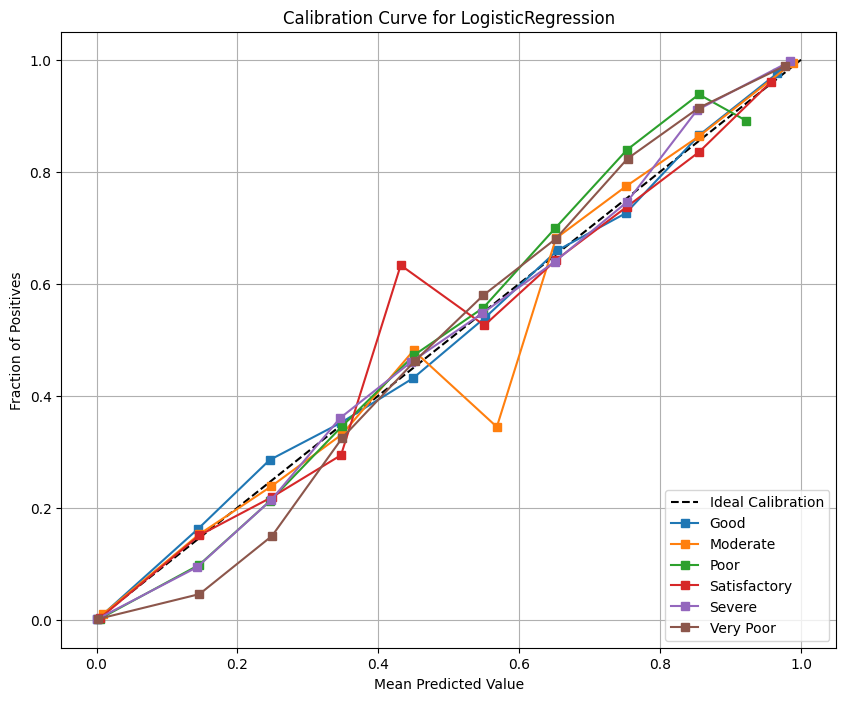

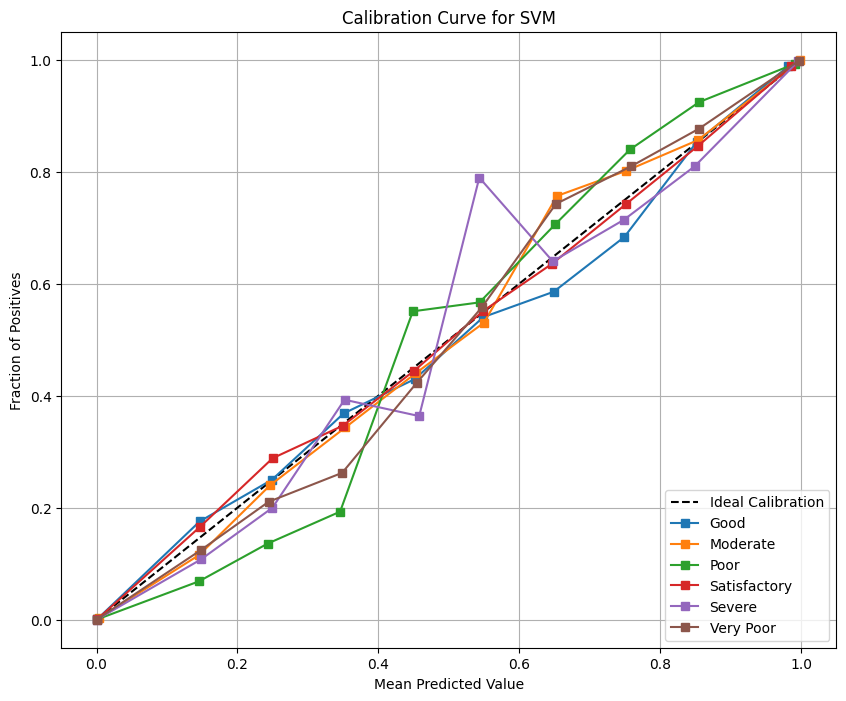

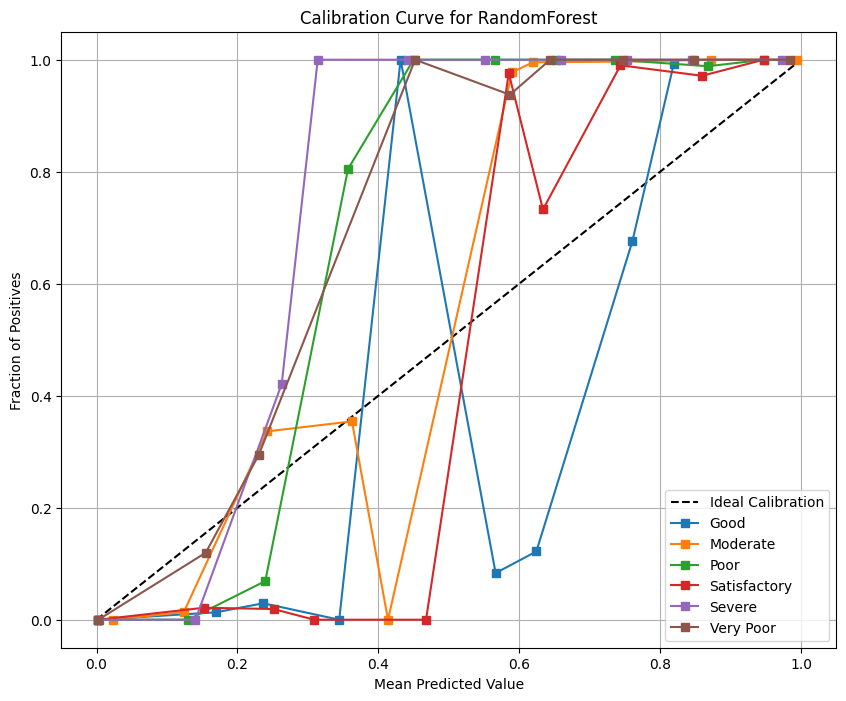

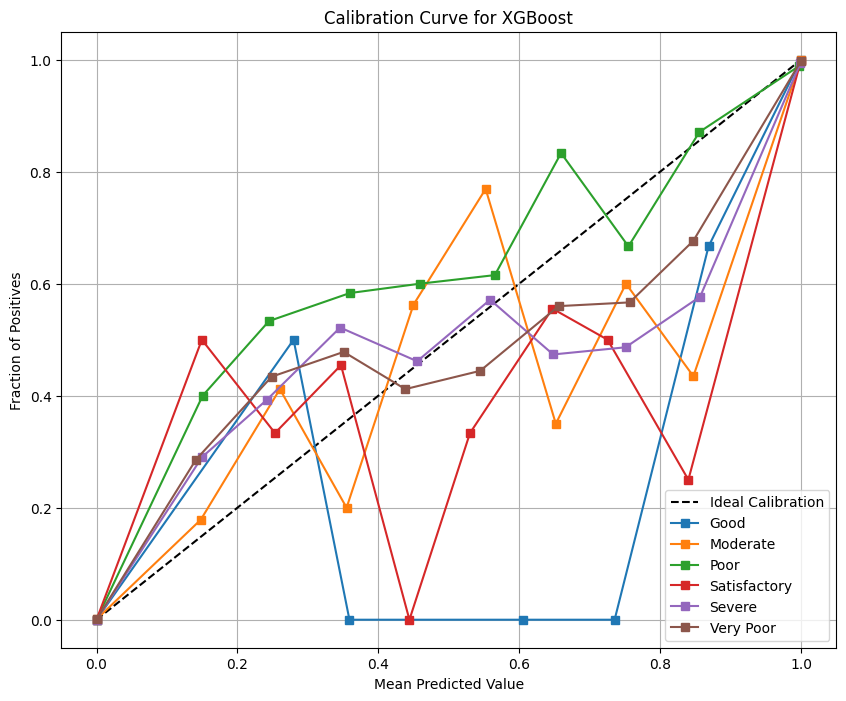

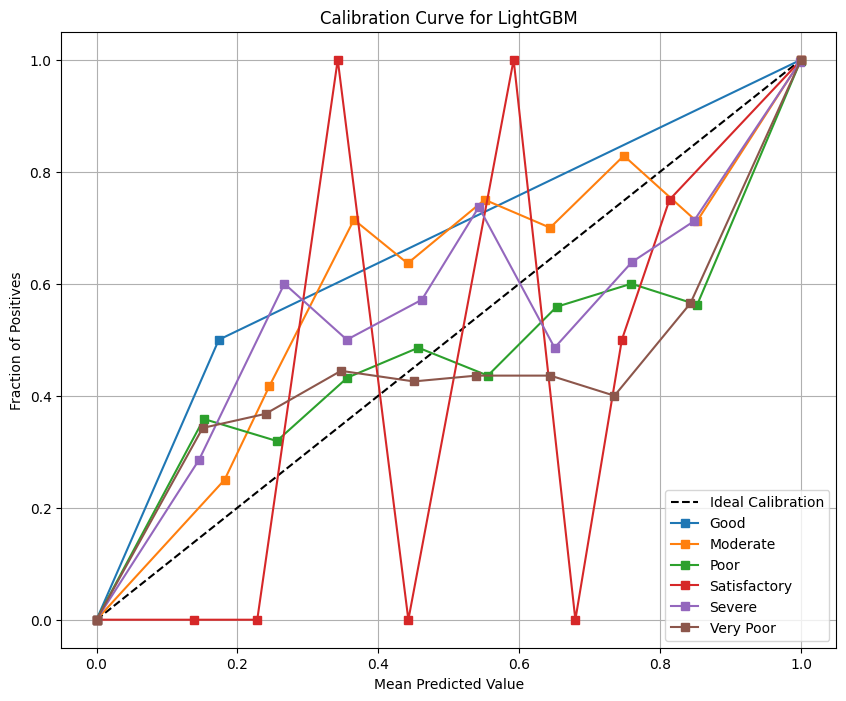

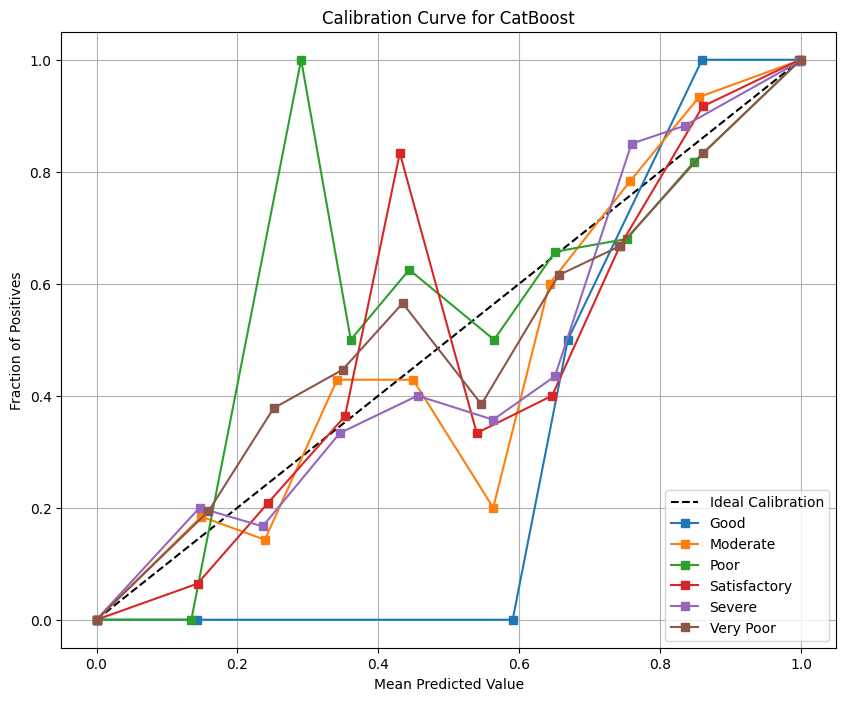

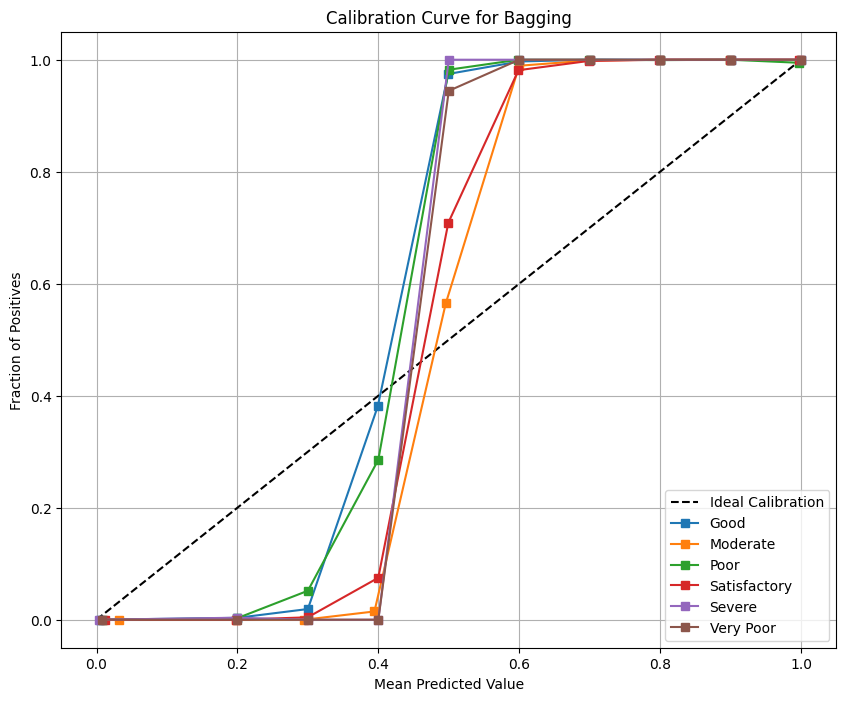

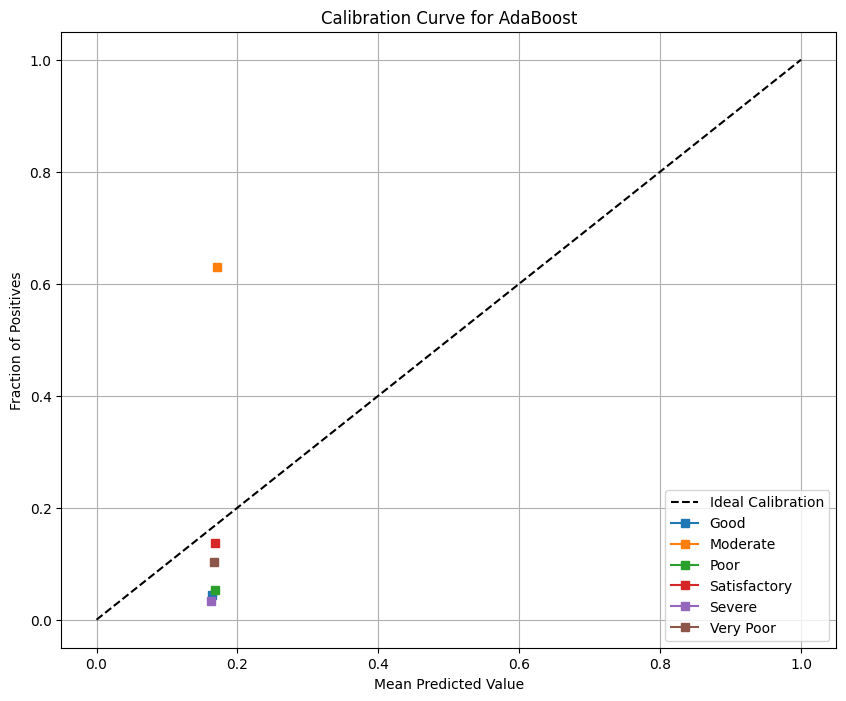

In [ ]:
plt.figure(figsize=(10, 8 * len(calibration_data)))
num_cols = 1  # One plot per row
num_models = len(calibration_data)
num_classes = len(label_enc.classes_)

for i, (name, class_data) in enumerate(calibration_data.items()):
    plt.figure(figsize=(10, 8)) # Create a new figure for each model
    ax = plt.gca()

    ax.plot([0, 1], [0, 1], 'k--', label='Ideal Calibration') # Plot ideal calibration line
    for class_name, data in class_data.items():
        ax.plot(data['mean_predicted_value'], data['fraction_of_positives'], 's-', label=f'{class_name}')
    ax.set_title(f'Calibration Curve for {name}')
    ax.set_xlabel('Mean Predicted Value')
    ax.set_ylabel('Fraction of Positives')
    ax.legend(loc='lower right')
    ax.grid(True)
    plt.show()

## Plot feature importance




Model LogisticRegression does not have feature_importances_ attribute.
Model SVM does not have feature_importances_ attribute.


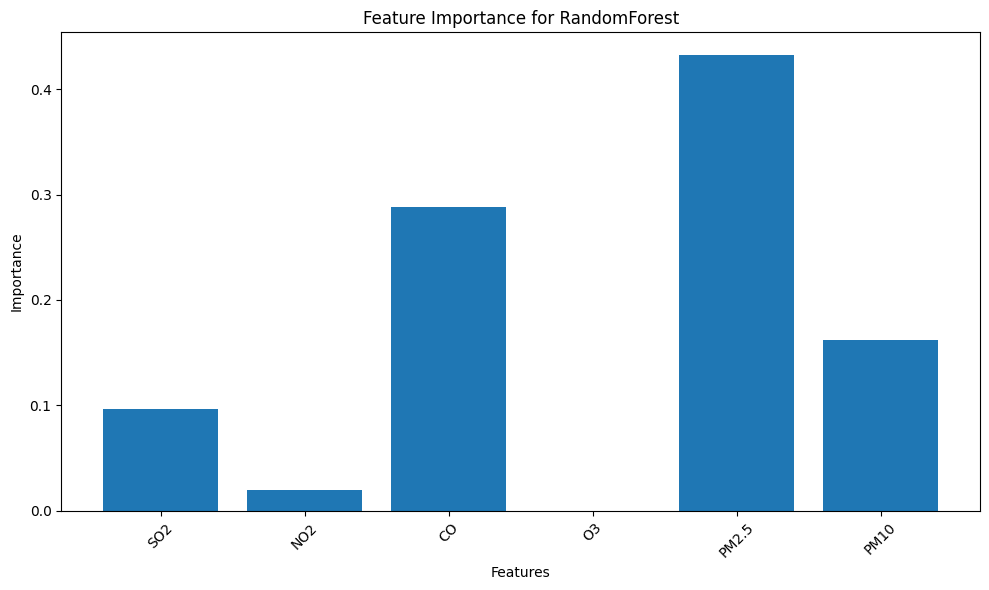

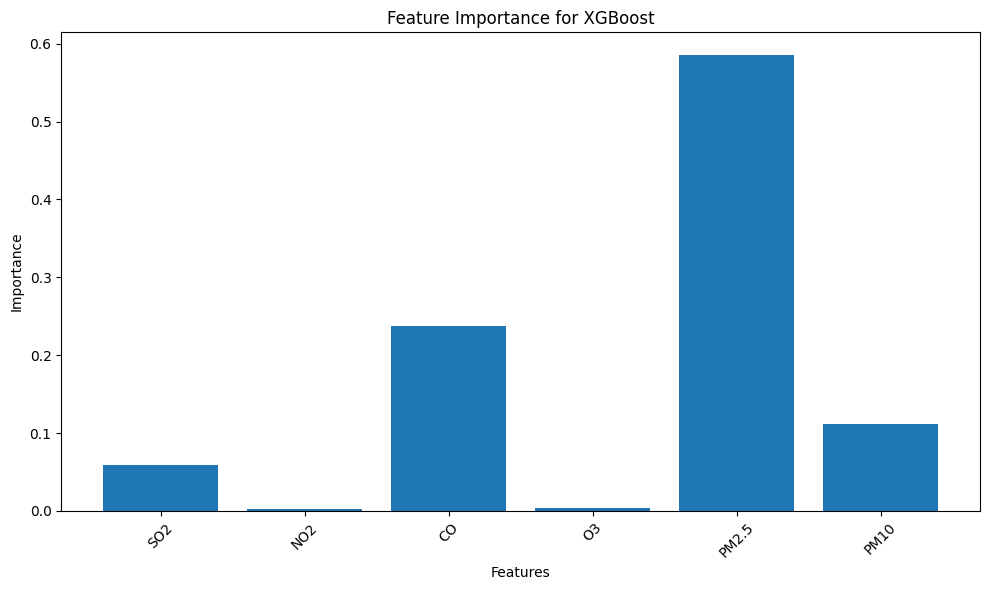

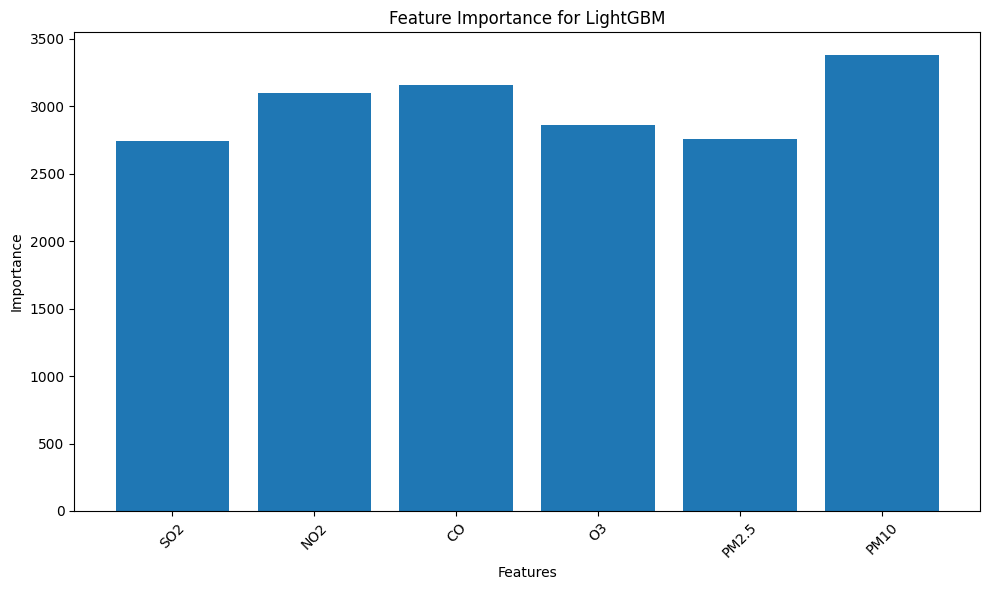

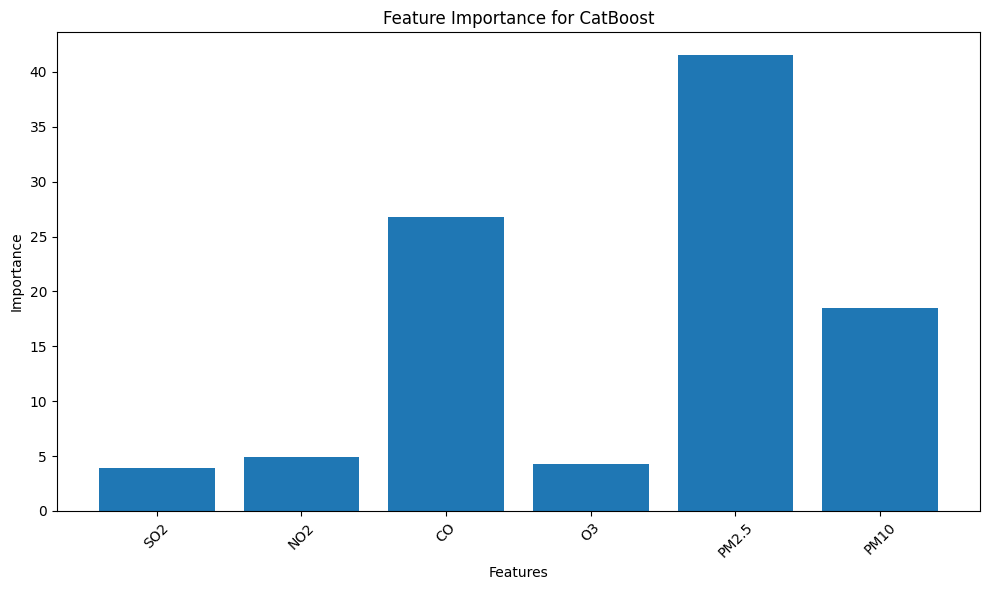

Model Bagging does not have feature_importances_ attribute.


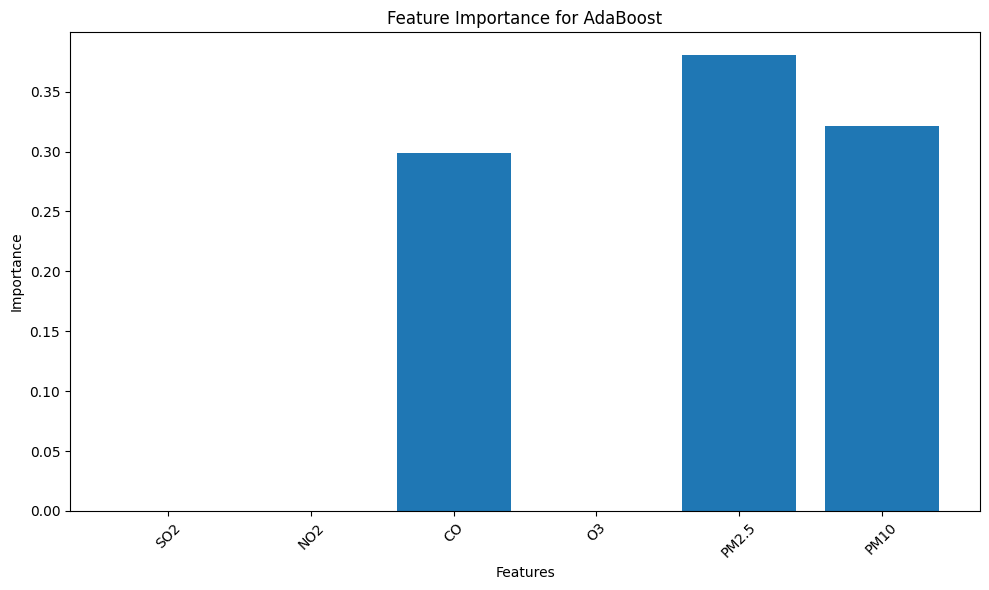

In [ ]:
for name, model in models.items():
    if hasattr(model, 'feature_importances_'):
        importances = model.feature_importances_
        feature_names = features # Use the defined features list
        plt.figure(figsize=(10, 6))
        plt.bar(feature_names, importances)
        plt.title(f'Feature Importance for {name}')
        plt.xlabel('Features')
        plt.ylabel('Importance')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
    else:
        print(f"Model {name} does not have feature_importances_ attribute.")

Dataset shape: (271326, 12)
AQI classes in encoded order: ['Good', 'Moderate', 'Poor', 'Satisfactory', 'Severe', 'Very Poor']
Class counts:
AQI_Category
Moderate        170940
Satisfactory     37263
Very Poor        28081
Poor             14400
Good             11800
Severe            8842
Name: count, dtype: int64
No missing predictor values: matching baseline StandardScaler preprocessing.
Train samples: 217,060; Test samples: 54,266

Training XGBoost...
XGBoost trained in 6.23 s

Training Bagging...
Bagging trained in 5.94 s

Training RandomForest...
RandomForest trained in 30.96 s
Full Ensemble (XGB + Bagging + RF): Acc=0.999410, Macro F1=0.999008, Macro AP=0.999788
Without XGBoost (Bagging + RF): Acc=0.997770, Macro F1=0.995306, Macro AP=0.999671
Without Bagging (XGB + RF): Acc=0.998415, Macro F1=0.996905, Macro AP=0.999879
Without Random Forest (XGB + Bagging): Acc=0.997752, Macro F1=0.994789, Macro AP=0.999690
XGBoost Only: Acc=0.995025, Macro F1=0.987691, Macro AP=0.999194
Baggi

,Configuration,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Macro AP
0,Full Ensemble (XGB + Bagging + RF),0.999410,0.999134,0.998884,0.999008,0.999788
1,Without XGBoost (Bagging + RF),0.997770,0.993556,0.997127,0.995306,0.999671
2,Without Bagging (XGB + RF),0.998415,0.997263,0.996550,0.996905,0.999879
3,Without Random Forest (XGB + Bagging),0.997752,0.995051,0.994531,0.994789,0.999690
4,XGBoost Only,0.995025,0.987176,0.988217,0.987691,0.999194
5,Bagging Only,0.997641,0.997697,0.994856,0.996269,0.999222
6,Random Forest Only,0.995854,0.989029,0.995288,0.992082,0.998730


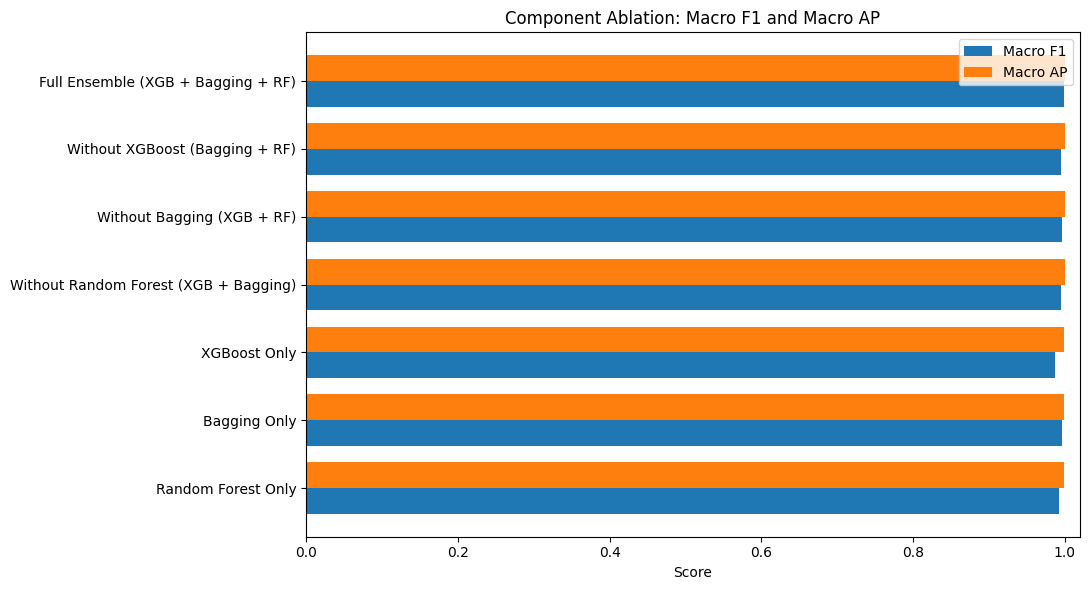


Saved to: /content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New
   Ablation_Overall_Performance.csv
   Ablation_Classwise_AP.csv
   Ablation_Confusion_Matrices.csv
   Ablation_Table.tex
   Ablation_MacroF1_MacroAP.png


In [ ]:


import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, average_precision_score,
    classification_report, confusion_matrix,
)
from xgboost import XGBClassifier

# ------------------------------------------------------------
# STEP 1: Mount Drive and load dataset
# ------------------------------------------------------------
from google.colab import drive
if not Path('/content/drive/MyDrive').exists():
    drive.mount('/content/drive')

SAVE_DIR = Path(
    '/content/drive/MyDrive/My work/'
    'Air Quality Project/Paper 1(External Data)/New/'
)
CSV_PATH = SAVE_DIR / 'merged_aqi_corrected_cleaned.csv'
SAVE_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(CSV_PATH)
features = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10']

required_columns = features + ['AQI_Category']
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f'Missing required columns: {missing_columns}')
if df['AQI_Category'].isna().any():
    raise ValueError('AQI_Category contains missing labels. Resolve before splitting.')

label_enc = LabelEncoder()
df['AQI_Label'] = label_enc.fit_transform(df['AQI_Category'])

n_classes = len(label_enc.classes_)
if n_classes != 6:
    raise ValueError(f'Expected six AQI classes, found {n_classes}: {list(label_enc.classes_)}')

# Convert only pollutant predictors to numeric (do not use AQI index as input).
X = df[features].apply(pd.to_numeric, errors='coerce')
y = df['AQI_Label']
class_ids = np.arange(n_classes)
class_names = list(label_enc.classes_)

print('Dataset shape:', df.shape)
print('AQI classes in encoded order:', class_names)
print('Class counts:')
print(df['AQI_Category'].value_counts())

# ------------------------------------------------------------
# STEP 2: Identical stratified 80/20 split
# ------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Only impute if needed. Any imputer is fitted to training data ONLY.
# If imputation is triggered, apply the SAME preprocessing to every
# baseline before treating their metrics as a controlled comparison.
if X_train.isna().any().any() or X_test.isna().any().any():
    print('Missing/non-numeric pollutant values found: using training-only median imputation.')
    imputer = SimpleImputer(strategy='median')
    X_train_array = imputer.fit_transform(X_train)
    X_test_array = imputer.transform(X_test)
else:
    print('No missing predictor values: matching baseline StandardScaler preprocessing.')
    imputer = None
    X_train_array = X_train.to_numpy(dtype=float)
    X_test_array = X_test.to_numpy(dtype=float)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_array)
X_test_scaled = scaler.transform(X_test_array)

y_train = np.asarray(y_train, dtype=int)
y_test = np.asarray(y_test, dtype=int)

if not np.array_equal(np.unique(y_train), class_ids):
    raise ValueError('All six categories must be present in the training partition.')
if not np.array_equal(np.unique(y_test), class_ids):
    raise ValueError('All six categories must be present in the test partition.')

y_test_binary = label_binarize(y_test, classes=class_ids)
print(f'Train samples: {len(y_train):,}; Test samples: {len(y_test):,}')

# ------------------------------------------------------------
# STEP 3: EXACT component settings from your baseline models
# (random_state=42 added for repeatability)
# ------------------------------------------------------------
models = {
    'XGBoost': XGBClassifier(
        use_label_encoder=False,
        eval_metric='mlogloss',
        random_state=42,
    ),
    'Bagging': BaggingClassifier(
        max_samples=0.8,
        max_features=0.8,
        random_state=42,
    ),
    'RandomForest': RandomForestClassifier(
        max_depth=6,
        max_features=0.8,
        random_state=42,
    ),
}

# ------------------------------------------------------------
# STEP 4: Train each component ONCE, on identical training data
# Cache class-aligned train and test probabilities.
# ------------------------------------------------------------
train_probabilities = {}
test_probabilities = {}
fit_seconds = {}

for name, model in models.items():
    print(f'\nTraining {name}...')
    t0 = time.perf_counter()
    model.fit(X_train_scaled, y_train)
    fit_seconds[name] = time.perf_counter() - t0

    if not np.array_equal(np.asarray(model.classes_, dtype=int), class_ids):
        raise ValueError(f'Unexpected class order for {name}: {model.classes_}')

    train_probabilities[name] = model.predict_proba(X_train_scaled)
    test_probabilities[name] = model.predict_proba(X_test_scaled)

    print(f'{name} trained in {fit_seconds[name]:.2f} s')

# ------------------------------------------------------------
# STEP 5: Seven ablation configurations (equal soft voting)
# ------------------------------------------------------------
variants = {
    'Full Ensemble (XGB + Bagging + RF)': ['XGBoost', 'Bagging', 'RandomForest'],
    'Without XGBoost (Bagging + RF)': ['Bagging', 'RandomForest'],
    'Without Bagging (XGB + RF)': ['XGBoost', 'RandomForest'],
    'Without Random Forest (XGB + Bagging)': ['XGBoost', 'Bagging'],
    'XGBoost Only': ['XGBoost'],
    'Bagging Only': ['Bagging'],
    'Random Forest Only': ['RandomForest'],
}

# ------------------------------------------------------------
# STEP 6: Evaluate each configuration on the SAME observations
# ------------------------------------------------------------
overall_rows = []
classwise_rows = []
confusion_rows = []

for variant, members in variants.items():
    train_proba = np.mean([train_probabilities[m] for m in members], axis=0)
    test_proba = np.mean([test_probabilities[m] for m in members], axis=0)

    train_pred = class_ids[np.argmax(train_proba, axis=1)]
    test_pred = class_ids[np.argmax(test_proba, axis=1)]

    per_class_ap = [
        average_precision_score(y_test_binary[:, i], test_proba[:, i])
        for i in range(n_classes)
    ]

    overall_rows.append({
        'Configuration': variant,
        'Train Accuracy': accuracy_score(y_train, train_pred),
        'Test Accuracy': accuracy_score(y_test, test_pred),
        'Train Macro F1': f1_score(y_train, train_pred, labels=class_ids,
                                   average='macro', zero_division=0),
        'Macro Precision': precision_score(y_test, test_pred, labels=class_ids,
                                           average='macro', zero_division=0),
        'Macro Recall': recall_score(y_test, test_pred, labels=class_ids,
                                     average='macro', zero_division=0),
        'Macro F1': f1_score(y_test, test_pred, labels=class_ids,
                             average='macro', zero_division=0),
        'Macro AP': float(np.mean(per_class_ap)),
        'Weighted F1': f1_score(y_test, test_pred, labels=class_ids,
                                average='weighted', zero_division=0),
        'Balanced Accuracy': balanced_accuracy_score(y_test, test_pred),
        'Support': int(len(y_test)),
        'Sum of Component Training Times (s)': sum(fit_seconds[m] for m in members),
    })

    report = classification_report(
        y_test, test_pred, labels=class_ids,
        target_names=class_names, output_dict=True, zero_division=0,
    )
    for i, label in enumerate(class_names):
        classwise_rows.append({
            'Configuration': variant,
            'AQI Category': label,
            'Precision': report[label]['precision'],
            'Recall': report[label]['recall'],
            'F1': report[label]['f1-score'],
            'AP': per_class_ap[i],
            'Support': int(report[label]['support']),
        })

    cm = confusion_matrix(y_test, test_pred, labels=class_ids)
    for i, actual in enumerate(class_names):
        for j, predicted in enumerate(class_names):
            confusion_rows.append({
                'Configuration': variant,
                'True Class': actual,
                'Predicted Class': predicted,
                'Count': int(cm[i, j]),
            })

    print(f"{variant}: Acc={overall_rows[-1]['Test Accuracy']:.6f}, "
          f"Macro F1={overall_rows[-1]['Macro F1']:.6f}, "
          f"Macro AP={overall_rows[-1]['Macro AP']:.6f}")

ablation_df = pd.DataFrame(overall_rows)
classwise_df = pd.DataFrame(classwise_rows)
confusion_df = pd.DataFrame(confusion_rows)

print('\n=== COMPLETE ABLATION RESULTS ===')
print(ablation_df.round(6).to_string(index=False))

# ------------------------------------------------------------
# STEP 7: Save CSVs to your dataset directory
# ------------------------------------------------------------
ablation_df.to_csv(SAVE_DIR / 'Ablation_Overall_Performance.csv', index=False)
classwise_df.to_csv(SAVE_DIR / 'Ablation_Classwise_AP.csv', index=False)
confusion_df.to_csv(SAVE_DIR / 'Ablation_Confusion_Matrices.csv', index=False)

# ------------------------------------------------------------
# STEP 8: Export ready-to-use LaTeX table
# ------------------------------------------------------------

# ============================================================
# STEP 8: PRINT NORMAL ABLATION RESULTS TABLE
# ============================================================

summary_columns = [
    "Configuration",
    "Test Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Macro AP"
]

summary_table = ablation_df[summary_columns].copy()

print("\n=== COMPONENT ABLATION COMPARISON ===")

print(
    summary_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# Display formatted table in Google Colab
from IPython.display import display

display(
    summary_table.style.format({
        col: "{:.6f}"
        for col in summary_columns[1:]
    })
)

# Save normal table as CSV
summary_table.to_csv(
    SAVE_DIR / "Ablation_Summary_Table.csv",
    index=False
)


# ------------------------------------------------------------
# STEP 9: Save Macro F1 and Macro AP comparison graphic
# ------------------------------------------------------------
plot_df = ablation_df.iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 6))
positions = np.arange(len(plot_df))
bar_h = 0.38
ax.barh(positions - bar_h / 2, plot_df['Macro F1'], height=bar_h,
        label='Macro F1')
ax.barh(positions + bar_h / 2, plot_df['Macro AP'], height=bar_h,
        label='Macro AP')
ax.set_yticks(positions)
ax.set_yticklabels(plot_df['Configuration'])
ax.set_xlim(0, 1.02)
ax.set_xlabel('Score')
ax.set_title('Component Ablation: Macro F1 and Macro AP')
ax.legend()
fig.tight_layout()
fig.savefig(SAVE_DIR / 'Ablation_MacroF1_MacroAP.png', dpi=300,
            bbox_inches='tight')
plt.show()

print('\nSaved to:', SAVE_DIR)
for filename in (
    'Ablation_Overall_Performance.csv',
    'Ablation_Classwise_AP.csv',
    'Ablation_Confusion_Matrices.csv',
    'Ablation_Table.tex',
    'Ablation_MacroF1_MacroAP.png',
):
    print('  ', filename)
